In [ ]:
import os
import glob
import pickle
import pandas as pd
import numpy as np

from dask.diagnostics import ProgressBar
import scipy.sparse
from arboreto.utils import load_tf_names
from arboreto.algo import grnboost2

from ctxcore.rnkdb import FeatherRankingDatabase as RankingDatabase
from pyscenic.utils import modules_from_adjacencies, load_motifs
from pyscenic.prune import prune2df, df2regulons
from pyscenic.aucell import aucell

import seaborn as sns
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
from pyscenic.cli.utils import load_exp_matrix
from pyscenic.prune import prune2df, df2regulons
from pyscenic.export import export2loom
from pyscenic.aucell import aucell
#from pyscenic.rnkdb import FeatherRankingDatabase as RankingDatabase
from pyscenic.utils import modules_from_adjacencies
from dask.diagnostics import ProgressBar

In [ ]:
adata_path = '/data/work/毕业文章/SGN/Merge-SGN-Final-pySCENIC.h5ad'
DATABASES_GLOB = '/data/work/毕业文章/Data/mm10__refseq-r80__*tss.mc9nr.genes_vs_motifs.rankings.feather'
# 需要从 https://resources.aertslab.org/cistarget/databases/mus_musculus/mm9/refseq_r45/mc9nr/gene_based/ 下载
MOTIF_ANNOTATIONS_FNAME = '/data/work/毕业文章/Data/motifs-v9-nr.mgi-m0.001-o0.0.tbl'
# https://resources.aertslab.org/cistarget/motif2tf/
REGULONS_FNAME = '/data/work/毕业文章/SGN/regulons.p'
MOTIFS_FNAME = '/data/work/毕业文章/SGN/motifs.csv'

In [ ]:
# 设置参数
ORGANISM = "mgi"  # 小鼠
OUTPUT_DIR = "Scenic"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. 加载数据 -----------------------------------------------------
adata = sc.read_h5ad(adata_path)

# 确认表达矩阵位置
print(f"表达矩阵形状: {adata.layers['counts'].shape}") 

# 1. 加载目标基因列表（无列名的txt文件）----------------------------------------
#with open("/data/work/其他/SCENIC/Database/hs_hgnc_tfs.txt", "r") as f:
#    target_genes = [line.strip() for line in f if line.strip()]  # 逐行读取并去除空行/空格

#print(f"初始目标基因数量: {len(target_genes)}")

# 2. 准备表达矩阵 ----------------------------------------------------------
# 从layers['counts']创建表达矩阵 (细胞×基因)
ex_matrix = pd.DataFrame(
    adata.layers['counts'].toarray() if scipy.sparse.issparse(adata.layers['counts']) else adata.layers['counts'],
    columns=adata.var_names,
    index=adata.obs_names
)

# 3. 过滤目标基因（确保大小写匹配）-------------------------------------------
#target_genes_in_data = [g for g in target_genes if g in ex_matrix.columns]
#print(f"在数据集中找到的目标基因数量: {len(target_genes_in_data)}")
#filtered_ex_matrix = ex_matrix[target_genes_in_data]

import pandas as pd
from arboreto.algo import grnboost2
import os

# 1. 加载TF列表 ----------------------------------------------------------
tf_list_path = "/data/work/毕业文章/Data/mm_mgi_tfs.txt"
tf_names = load_tf_names(tf_list_path)
# 读取TF列表文件（纯文本，每行一个基因名）
#with open(tf_list_path, 'r') as f:
#    known_tfs = [line.strip() for line in f if line.strip()]  # 去除空白行和每行首尾空格#

#print(f"已知TF数量: {len(known_tfs)}")
#print("示例TF:", known_tfs[:5])  # 检查前5个TF

# 2. 筛选目标基因中的已知TF ----------------------------------------------
# 假设 target_genes_in_data 是你的目标基因列表（Symbol格式）
# target_genes_in_data = [...]  # 你的目标基因列表（需提前定义）

# 取交集：筛选目标基因中真实存在的TF
#tfs_in_target = list(set(target_genes_in_data) & set(known_tfs))

#print(f"目标基因中的已知TF数量: {len(tfs_in_target)}")
#print("示例TF in target:", tfs_in_target[:5])

表达矩阵形状: (232, 65980)


In [ ]:
print(adata)

AnnData object with n_obs × n_vars = 232 × 65980
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sample', 'percent.mt', 'RNA_snn_res.0.5', 'seurat_clusters', 'source', 'SN', 'RNA_snn_res.0.8', 'RNA_snn_res.0.4', 'RNA_snn_res.0.3', 'integrated_snn_res.0.3', 'celltype', 'celltype_0813', 'scDblFinder.class', 'scDblFinder.score', 'integrated_snn_res.0.7', 'subtype', 'integrated_snn_res.0.5', 'subtype_0915', 'integrated_snn_res.1', 'SGN_subtype', 'integrated_snn_res.1.5', 'subtype_Final', 'subtype_Final_new'
    var: 'features', 'Gene'
    layers: 'counts'


In [ ]:
import scanpy as sc

adata.layers["counts"] = adata.X.copy()

# 1. 数据预处理
sc.pp.filter_genes(adata, min_cells=10)  # 过滤在少于10个细胞中表达的基因
sc.pp.normalize_total(adata, target_sum=1e4)  # 标准化
sc.pp.log1p(adata)  # log转换

# 2. 计算高变基因
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=5000,  # 选择5000个高变基因
    flavor='seurat',   # 使用Seurat的方法
    batch_key=None     # 如果有批次效应，可以指定批次列
)

# 3. 筛选高变基因
adata_hvg = adata[:, adata.var.highly_variable].copy()

# 检查结果
print(f"原始基因数: {adata.n_vars}")
print(f"筛选后高变基因数: {adata_hvg.n_vars}")

原始基因数: 10950
筛选后高变基因数: 5000


In [ ]:
from dask.distributed import Client, LocalCluster
# 降采样到 100,000 个细胞（随机取样）
import numpy as np
from arboreto.algo import grnboost2
from dask.distributed import Client
np.random.seed(42)
# sampled_cells = np.random.choice(ex_matrix.shape[0], size=10000)
# ex_matrix = ex_matrix.iloc[sampled_cells, :]
# client = Client(n_workers=60, threads_per_worker=4)

In [ ]:
hvg_genes = adata.var_names[adata.var.highly_variable]
print(f"高变基因数量: {len(hvg_genes)}")

ex_matrix_hvg = ex_matrix.loc[:, ex_matrix.columns.intersection(hvg_genes)]
print(f"筛选后的表达矩阵形状: {ex_matrix_hvg.shape}")
# 假设tf_names是之前加载的TF列表
tf_names_hvg = list(set(tf_names) & set(hvg_genes))
print(f"高变基因中的TF数量: {len(tf_names_hvg)}")

高变基因数量: 5000
筛选后的表达矩阵形状: (232, 5000)
高变基因中的TF数量: 370


In [ ]:
client = Client(n_workers=60, threads_per_worker=8)
# 运行 GRNBoost2
adjacencies = grnboost2(
    expression_data=ex_matrix_hvg,
    tf_names=tf_names,
    client_or_address=client,
    verbose=True# 显式传递 client
)

/opt/software/python/lib/python3.8/site-packages/distributed/node.py:182: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 38623 instead
  warnings.warn(


preparing dask client
parsing input
creating dask graph
60 partitions
computing dask graph


/opt/software/python/lib/python3.8/site-packages/distributed/client.py:3108: UserWarning: Sending large graph of size 11.21 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


not shutting down client, client was created externally
finished


In [ ]:
# 保存结果
adjacencies.to_csv(os.path.join(OUTPUT_DIR, "SGN_adjacencies.csv"), index=False)
print(f"生成的调控关系数量: {len(adjacencies)}")

生成的调控关系数量: 392707


In [ ]:
db_fnames = glob.glob(DATABASES_GLOB)
def name(fname):
    return os.path.splitext(os.path.basename(fname))[0]
dbs = [RankingDatabase(fname=fname, name=name(fname)) for fname in db_fnames]
dbs

#从共表达网络构建模块
modules = list(modules_from_adjacencies(adjacencies, ex_matrix))

# 提取所有 Regulon 的 TF、靶基因和权重
data = []
for regulon in modules:
    tf = regulon.name.replace('Regulon for ', '')  # 从 "Regulon for HMGA1" 提取 "HMGA1"
    for target, weight in regulon.gene2weight.items():
        data.append({"TF": tf, "Target": target, "Weight": weight})

# 转换为 DataFrame 并保存
df = pd.DataFrame(data)
df.to_csv("SGN_regulons_tf_target_weight.csv", index=False)


2026-10-15 14:46:39,785 - pyscenic.utils - INFO - Calculating Pearson correlations.

2026-10-15 14:46:39,932 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2026-10-15 14:46:44,168 - pyscenic.utils - INFO - Creating modules.


In [ ]:
# 读取 CSV 文件
df = pd.read_csv("SGN_regulons_tf_target_weight.csv") 

# 按 TF 分组，统计每个 TF 的靶基因数量
tf_stats = df.groupby("TF").agg(
    Num_Targets=("Target", "count"),      # 统计靶基因数量
    Target_List=("Target", lambda x: "、".join(x)),  # 用顿号连接所有靶基因
    Mean_Weight=("Weight", "mean")        # 计算平均权重
).reset_index()

# 保存结果
tf_stats.to_csv("SGN_tf_summary.csv", index=False, encoding="utf-8-sig")
print("统计结果已保存为: Epi_tf_summary.csv")

统计结果已保存为: Epi_tf_summary.csv


In [ ]:
# 计算富集基序
# Calculate a list of enriched motifs and the corresponding target genes for all modules.
with ProgressBar():
    df = prune2df(dbs, modules, MOTIF_ANNOTATIONS_FNAME)

# Create regulons from this table of enriched motifs.
regulons = df2regulons(df)

[                                        ] | 0% Completed | 119.93 ms

/opt/software/python/lib/python3.8/site-packages/dask/base.py:1368: UserWarning: Running on a single-machine scheduler when a distributed client is active might lead to unexpected results.
  warnings.warn(


[                                        ] | 0% Completed | 37.91 sms


2026-10-15 14:47:59,243 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for Sox12 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.

2026-10-15 14:47:59,293 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for Arid5b could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.


[                                        ] | 0% Completed | 39.83 s

...

[#############################           ] | 73% Completed | 207.53 s


2026-10-15 14:50:48,796 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for Zfp664 could be mapped to mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.


[##################################      ] | 86% Completed | 208.64 s


2026-10-15 14:50:49,947 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for Smap2 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.


[########################################] | 100% Completed | 209.38 s
Create regulons from a dataframe of enriched features.
Additional columns saved: []


In [ ]:
# Save the enriched motifs and the discovered regulons to disk.
df.to_csv(MOTIFS_FNAME)
with open(REGULONS_FNAME, "wb") as f:
    pickle.dump(regulons, f)

num_regulons = len(regulons)
print(f"Number of regulons: {num_regulons}")

Number of regulons: 93


/opt/software/python/lib/python3.8/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


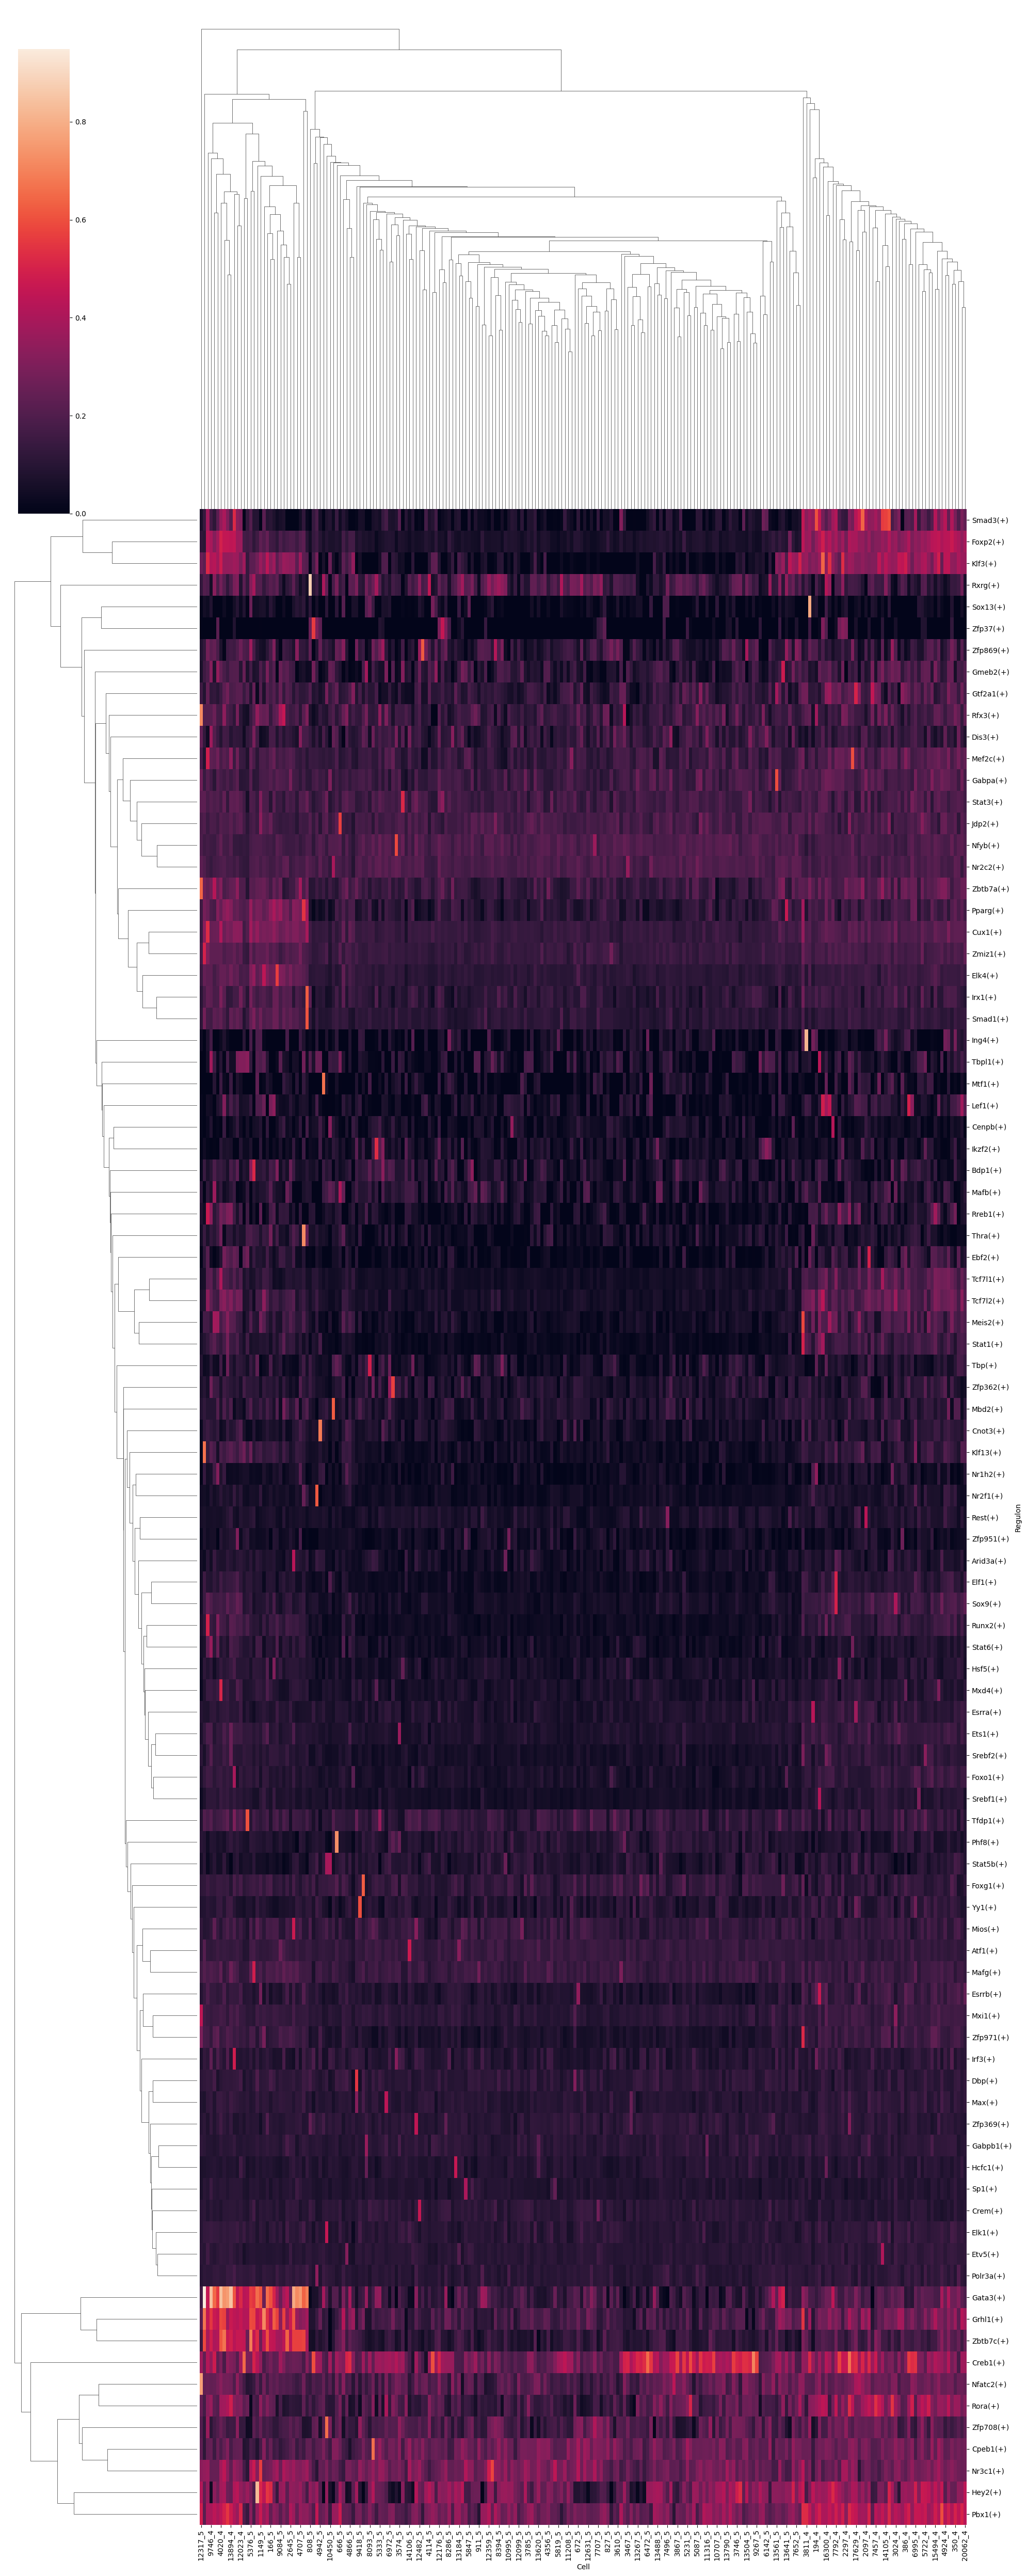

In [ ]:
auc_mtx = aucell(ex_matrix, regulons, num_workers=60)
auc_mtx.to_csv(os.path.join(OUTPUT_DIR, "SGN_auc_matrix.csv"))
# 创建热图
g = sns.clustermap(auc_mtx.T, col_cluster=True, figsize=(20, 50))

# 保存为 PDF 文件
g.savefig("SGN_motif_heatmap.pdf", format="pdf", bbox_inches="tight")

/opt/software/python/lib/python3.8/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


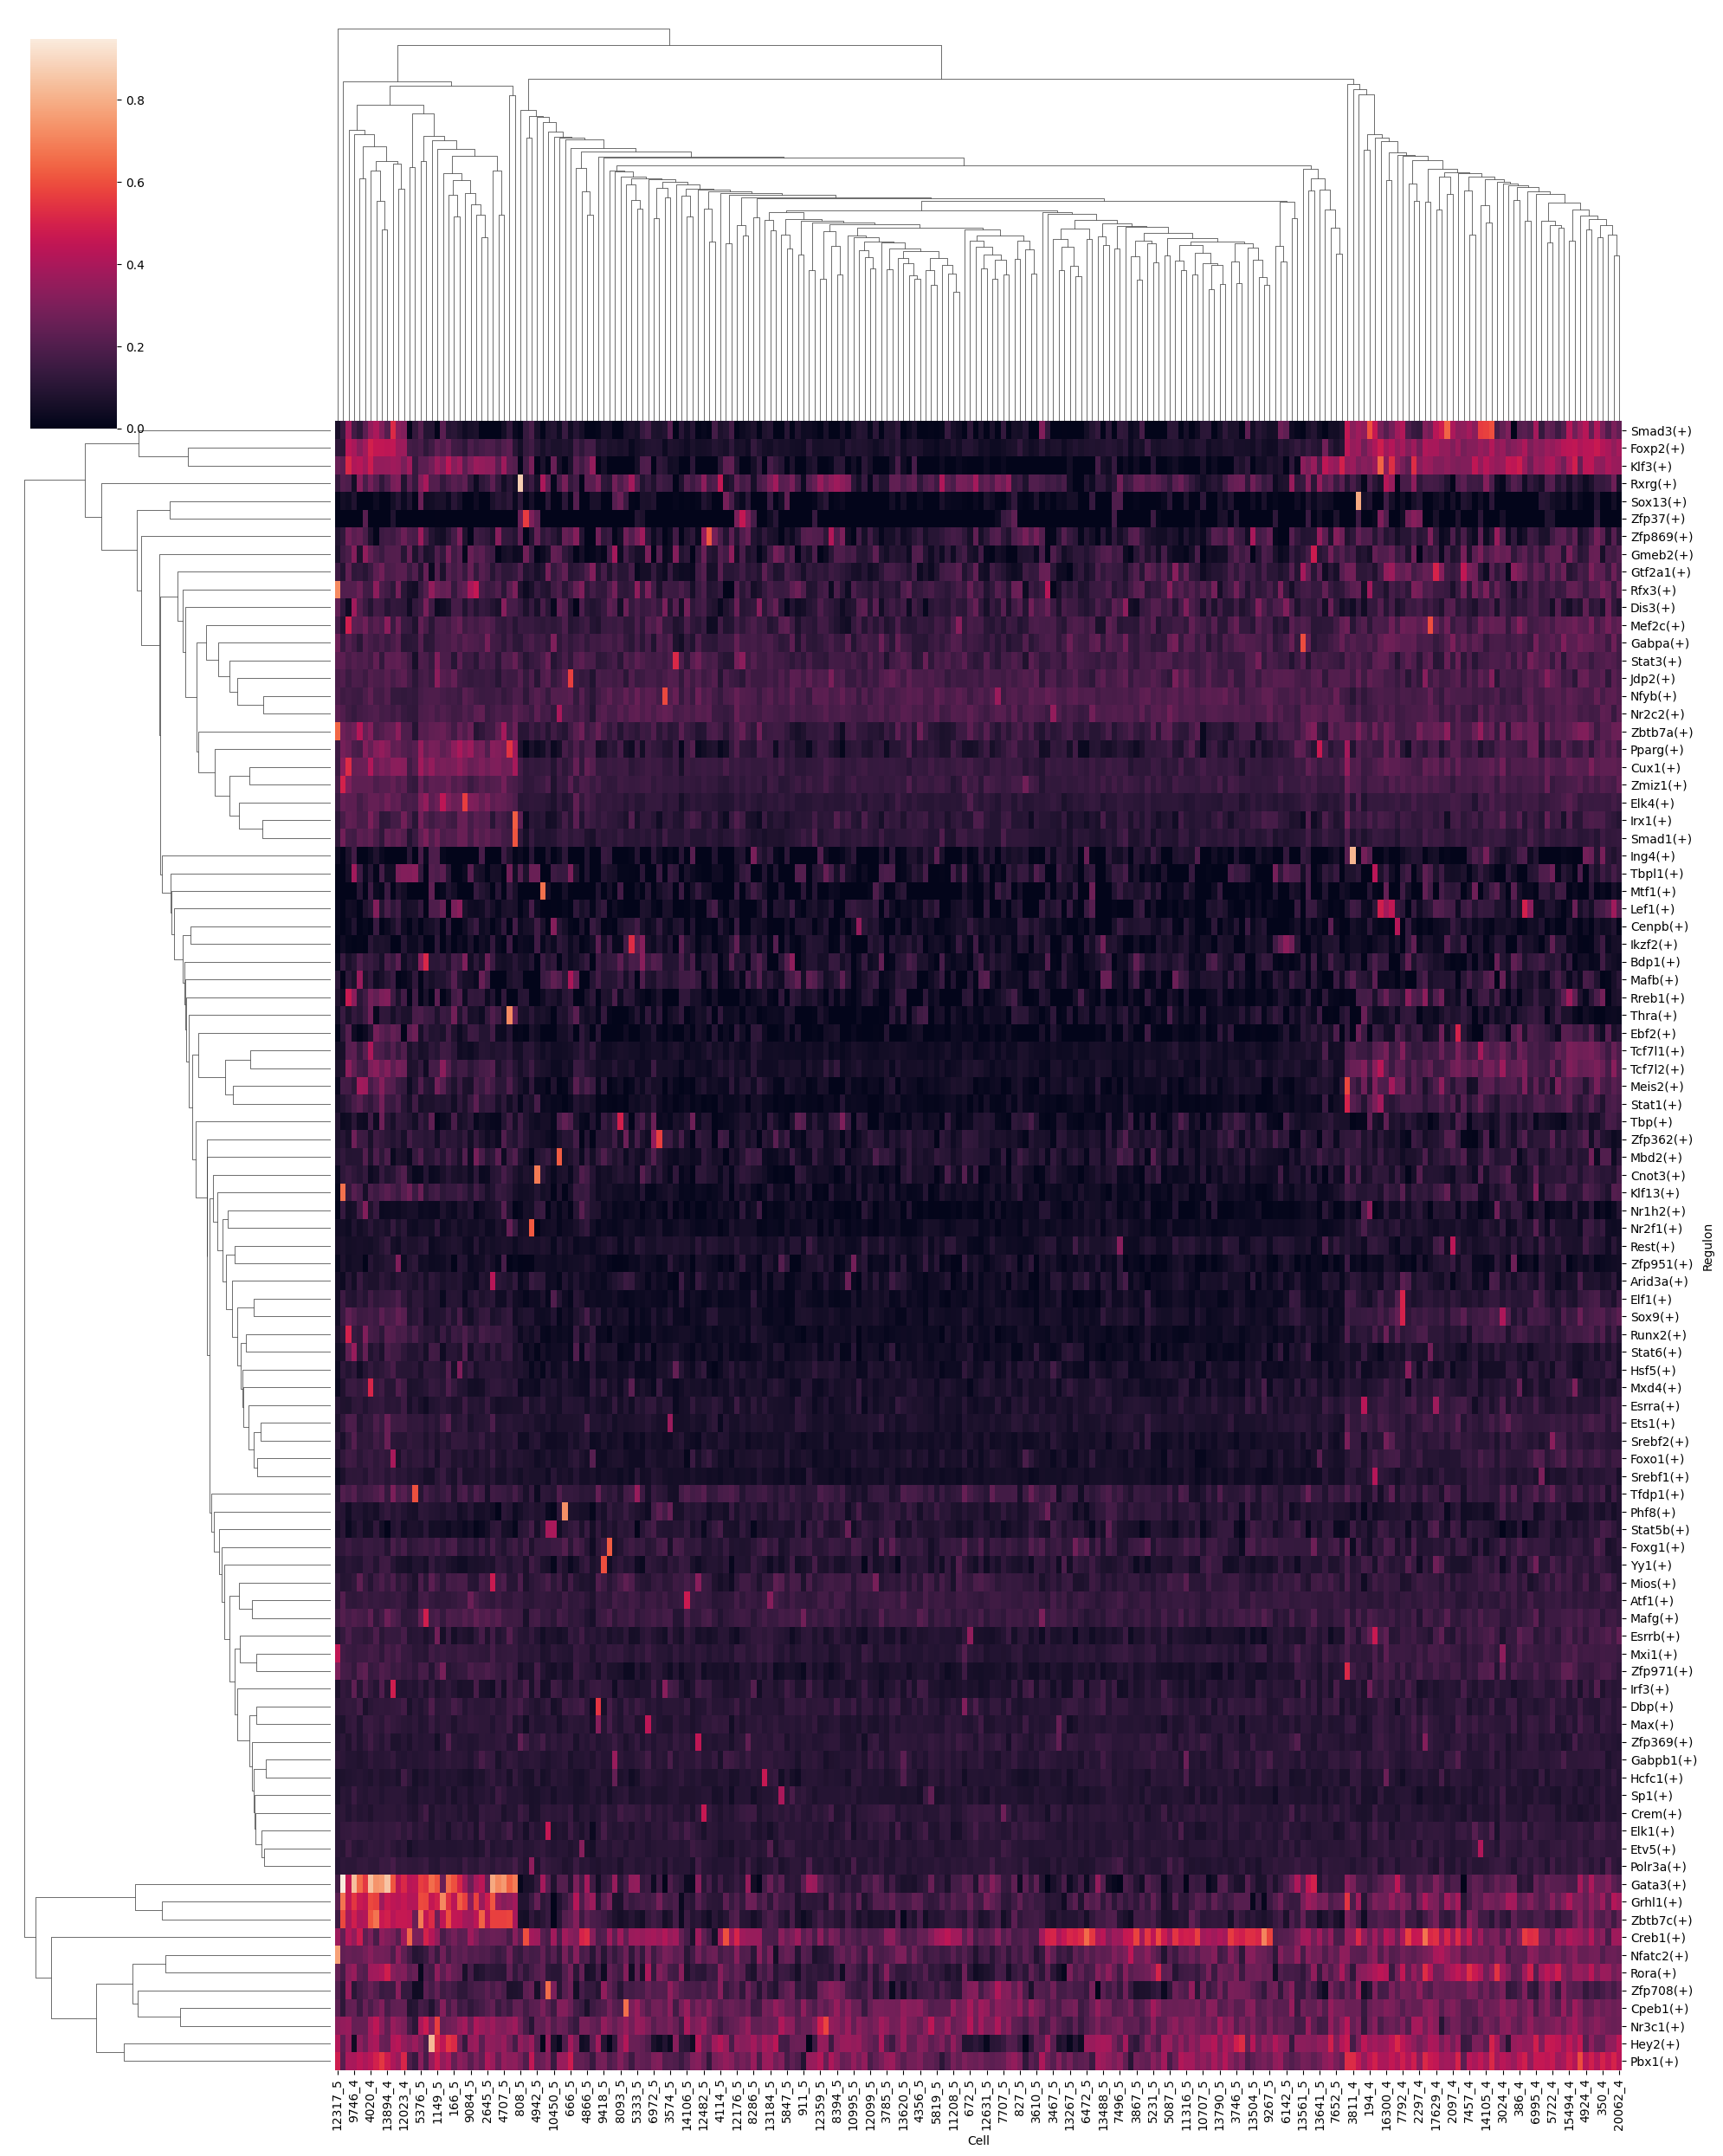

In [ ]:
g = sns.clustermap(auc_mtx.T, col_cluster=True, figsize=(20, 25))

# 保存为 PDF 文件
g.savefig("SGN_motif_heatmap_25.pdf", format="pdf", bbox_inches="tight")

/opt/software/python/lib/python3.8/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


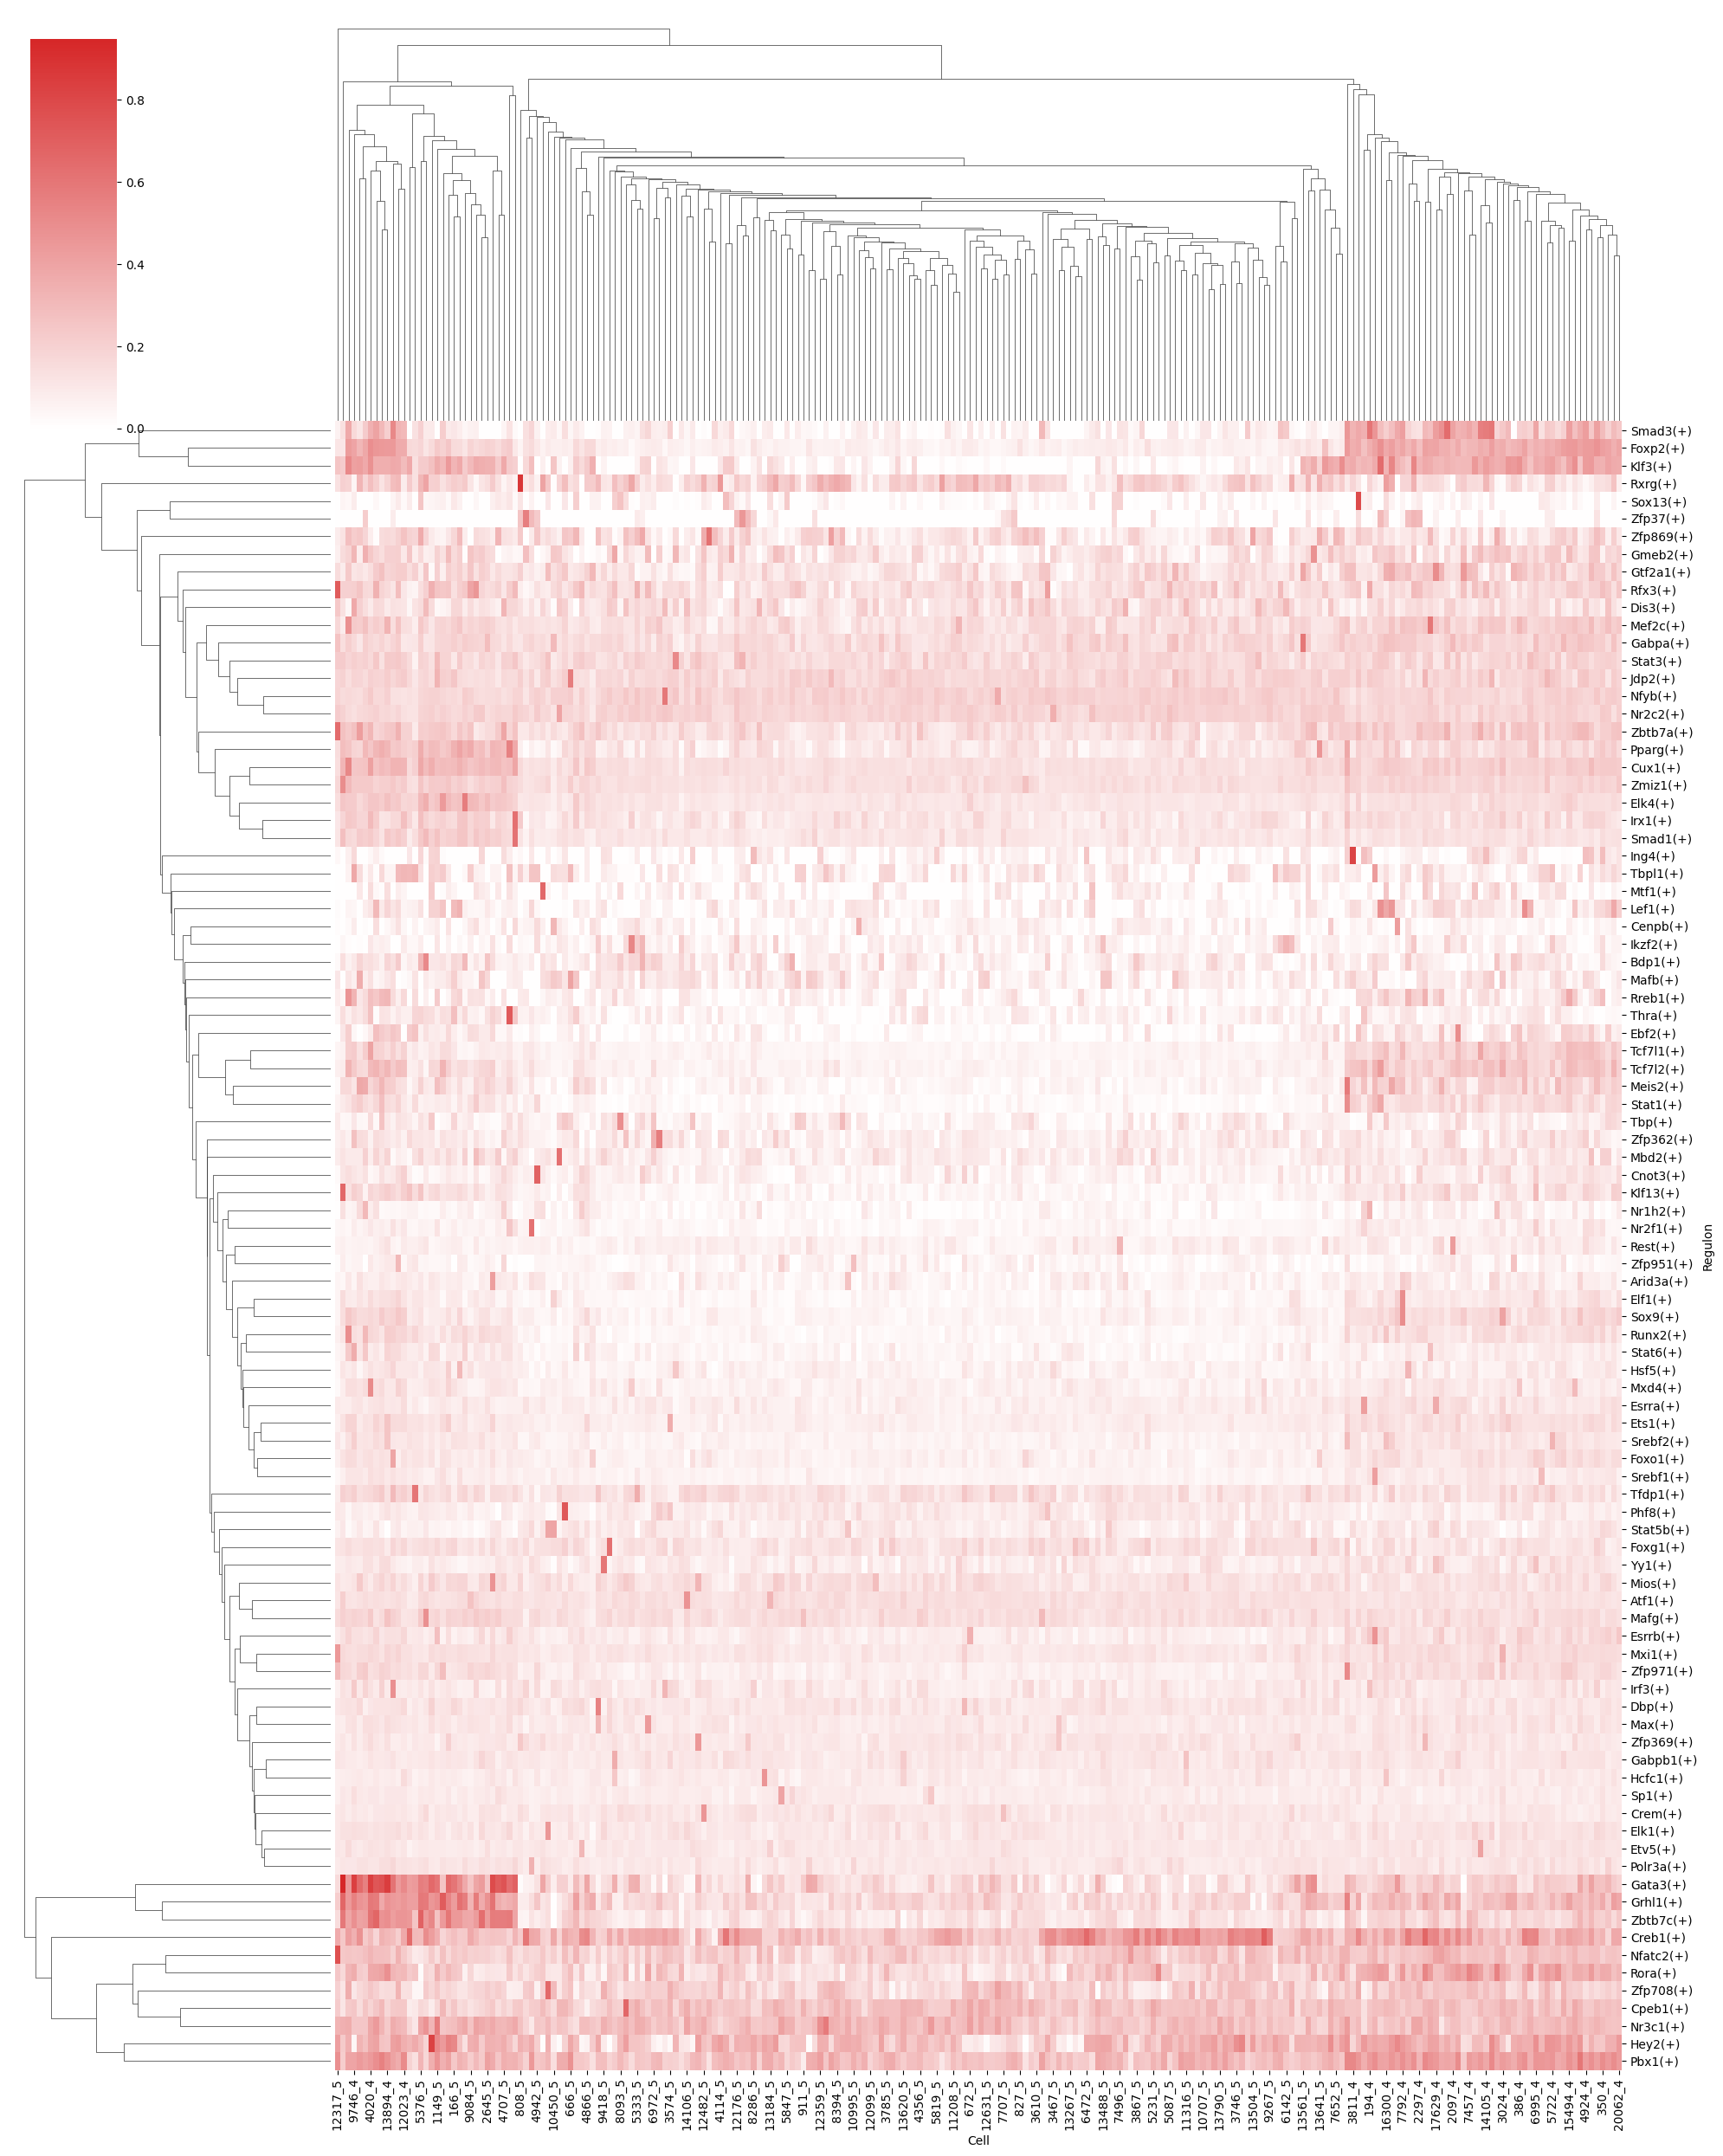

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

custom_cmap = LinearSegmentedColormap.from_list(
    'custom_bwr', ['#1f77b4', '#ffffff', '#d62728']  # 蓝, 白, 红
)

g = sns.clustermap(
    auc_mtx.T,
    col_cluster=True,
    figsize=(20, 25),
    cmap=custom_cmap,  # 使用自定义色彩
    center=0
)
g.savefig("SGN_motif_heatmap_red.pdf", format="pdf", bbox_inches="tight")

In [ ]:
adata_path = '/data/work/毕业文章/Glia/Data/Merge-Glia-Final-pySCENIC.h5ad'
DATABASES_GLOB = '/data/work/毕业文章/Data/mm10__refseq-r80__*tss.mc9nr.genes_vs_motifs.rankings.feather'
# 需要从 https://resources.aertslab.org/cistarget/databases/mus_musculus/mm9/refseq_r45/mc9nr/gene_based/ 下载
MOTIF_ANNOTATIONS_FNAME = '/data/work/毕业文章/Data/motifs-v9-nr.mgi-m0.001-o0.0.tbl'
# https://resources.aertslab.org/cistarget/motif2tf/
REGULONS_FNAME = '/data/work/毕业文章/Glia/Scenic/regulons.p'
MOTIFS_FNAME = '/data/work/毕业文章/Glia/Scenic/motifs.csv'

In [ ]:
# 设置参数
ORGANISM = "mgi"  # 小鼠
OUTPUT_DIR = "Scenic"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. 加载数据 -----------------------------------------------------
adata = sc.read_h5ad(adata_path)

# 确认表达矩阵位置
print(f"表达矩阵形状: {adata.layers['counts'].shape}") 

# 1. 加载目标基因列表（无列名的txt文件）----------------------------------------
#with open("/data/work/其他/SCENIC/Database/hs_hgnc_tfs.txt", "r") as f:
#    target_genes = [line.strip() for line in f if line.strip()]  # 逐行读取并去除空行/空格

#print(f"初始目标基因数量: {len(target_genes)}")

# 2. 准备表达矩阵 ----------------------------------------------------------
# 从layers['counts']创建表达矩阵 (细胞×基因)
ex_matrix = pd.DataFrame(
    adata.layers['counts'].toarray() if scipy.sparse.issparse(adata.layers['counts']) else adata.layers['counts'],
    columns=adata.var_names,
    index=adata.obs_names
)

# 3. 过滤目标基因（确保大小写匹配）-------------------------------------------
#target_genes_in_data = [g for g in target_genes if g in ex_matrix.columns]
#print(f"在数据集中找到的目标基因数量: {len(target_genes_in_data)}")
#filtered_ex_matrix = ex_matrix[target_genes_in_data]

import pandas as pd
from arboreto.algo import grnboost2
import os

# 1. 加载TF列表 ----------------------------------------------------------
tf_list_path = "/data/work/毕业文章/Data/mm_mgi_tfs.txt"
tf_names = load_tf_names(tf_list_path)
# 读取TF列表文件（纯文本，每行一个基因名）
#with open(tf_list_path, 'r') as f:
#    known_tfs = [line.strip() for line in f if line.strip()]  # 去除空白行和每行首尾空格#

#print(f"已知TF数量: {len(known_tfs)}")
#print("示例TF:", known_tfs[:5])  # 检查前5个TF

# 2. 筛选目标基因中的已知TF ----------------------------------------------
# 假设 target_genes_in_data 是你的目标基因列表（Symbol格式）
# target_genes_in_data = [...]  # 你的目标基因列表（需提前定义）

# 取交集：筛选目标基因中真实存在的TF
#tfs_in_target = list(set(target_genes_in_data) & set(known_tfs))

#print(f"目标基因中的已知TF数量: {len(tfs_in_target)}")
#print("示例TF in target:", tfs_in_target[:5])

表达矩阵形状: (1913, 65980)


In [ ]:
print(adata)

AnnData object with n_obs × n_vars = 1913 × 65980
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sample', 'percent.mt', 'RNA_snn_res.0.5', 'seurat_clusters', 'source', 'SN', 'RNA_snn_res.0.8', 'RNA_snn_res.0.4', 'RNA_snn_res.0.3', 'integrated_snn_res.0.3', 'celltype', 'celltype_0813', 'scDblFinder.class', 'scDblFinder.score', 'integrated_snn_res.0.7', 'subtype', 'integrated_snn_res.1', 'Glia_subtype'
    var: 'Gene'
    layers: 'counts'


In [ ]:
import scanpy as sc

adata.layers["counts"] = adata.X.copy()

# 1. 数据预处理
sc.pp.filter_genes(adata, min_cells=10)  # 过滤在少于10个细胞中表达的基因
sc.pp.normalize_total(adata, target_sum=1e4)  # 标准化
sc.pp.log1p(adata)  # log转换

# 2. 计算高变基因
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=5000,  # 选择5000个高变基因
    flavor='seurat',   # 使用Seurat的方法
    batch_key=None     # 如果有批次效应，可以指定批次列
)

# 3. 筛选高变基因
adata_hvg = adata[:, adata.var.highly_variable].copy()

# 检查结果
print(f"原始基因数: {adata.n_vars}")
print(f"筛选后高变基因数: {adata_hvg.n_vars}")

原始基因数: 16532
筛选后高变基因数: 5000


In [ ]:
from dask.distributed import Client, LocalCluster
# 降采样到 100,000 个细胞（随机取样）
import numpy as np
from arboreto.algo import grnboost2
from dask.distributed import Client
np.random.seed(42)
# sampled_cells = np.random.choice(ex_matrix.shape[0], size=10000)
# ex_matrix = ex_matrix.iloc[sampled_cells, :]
# client = Client(n_workers=60, threads_per_worker=4)

In [ ]:
hvg_genes = adata.var_names[adata.var.highly_variable]
print(f"高变基因数量: {len(hvg_genes)}")

ex_matrix_hvg = ex_matrix.loc[:, ex_matrix.columns.intersection(hvg_genes)]
print(f"筛选后的表达矩阵形状: {ex_matrix_hvg.shape}")
# 假设tf_names是之前加载的TF列表
tf_names_hvg = list(set(tf_names) & set(hvg_genes))
print(f"高变基因中的TF数量: {len(tf_names_hvg)}")

高变基因数量: 5000
筛选后的表达矩阵形状: (1913, 5000)
高变基因中的TF数量: 305


In [ ]:
client = Client(n_workers=60, threads_per_worker=8)
# 运行 GRNBoost2
adjacencies = grnboost2(
    expression_data=ex_matrix_hvg,
    tf_names=tf_names,
    client_or_address=client,
    verbose=True# 显式传递 client
)

preparing dask client
parsing input
creating dask graph
60 partitions
computing dask graph


/opt/software/python/lib/python3.8/site-packages/distributed/client.py:3108: UserWarning: Sending large graph of size 75.35 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


not shutting down client, client was created externally
finished


In [ ]:
# 保存结果
adjacencies.to_csv(os.path.join(OUTPUT_DIR, "Glia_adjacencies.csv"), index=False)
print(f"生成的调控关系数量: {len(adjacencies)}")

生成的调控关系数量: 363518


In [ ]:
db_fnames = glob.glob(DATABASES_GLOB)
def name(fname):
    return os.path.splitext(os.path.basename(fname))[0]
dbs = [RankingDatabase(fname=fname, name=name(fname)) for fname in db_fnames]
dbs

#从共表达网络构建模块
modules = list(modules_from_adjacencies(adjacencies, ex_matrix))

# 提取所有 Regulon 的 TF、靶基因和权重
data = []
for regulon in modules:
    tf = regulon.name.replace('Regulon for ', '')  # 从 "Regulon for HMGA1" 提取 "HMGA1"
    for target, weight in regulon.gene2weight.items():
        data.append({"TF": tf, "Target": target, "Weight": weight})

# 转换为 DataFrame 并保存
df = pd.DataFrame(data)
df.to_csv("Glia_regulons_tf_target_weight.csv", index=False)


2026-10-14 22:14:17,097 - pyscenic.utils - INFO - Calculating Pearson correlations.

2026-10-14 22:14:17,244 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2026-10-14 22:14:20,641 - pyscenic.utils - INFO - Creating modules.


In [ ]:
# 读取 CSV 文件
df = pd.read_csv("Glia_regulons_tf_target_weight.csv") 

# 按 TF 分组，统计每个 TF 的靶基因数量
tf_stats = df.groupby("TF").agg(
    Num_Targets=("Target", "count"),      # 统计靶基因数量
    Target_List=("Target", lambda x: "、".join(x)),  # 用顿号连接所有靶基因
    Mean_Weight=("Weight", "mean")        # 计算平均权重
).reset_index()

# 保存结果
tf_stats.to_csv("Glia_tf_summary.csv", index=False, encoding="utf-8-sig")
print("统计结果已保存为: e4_LE_tf_summary.csv")

统计结果已保存为: e4_LE_tf_summary.csv


In [ ]:
# 计算富集基序
# Calculate a list of enriched motifs and the corresponding target genes for all modules.
with ProgressBar():
    df = prune2df(dbs, modules, MOTIF_ANNOTATIONS_FNAME)

# Create regulons from this table of enriched motifs.
regulons = df2regulons(df)

[                                        ] | 0% Completed | 117.81 ms

/opt/software/python/lib/python3.8/site-packages/dask/base.py:1368: UserWarning: Running on a single-machine scheduler when a distributed client is active might lead to unexpected results.
  warnings.warn(


[                                        ] | 0% Completed | 51.40 sms


2026-10-14 22:16:07,169 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for 3300002I08Rik could be mapped to mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.


[                                        ] | 0% Completed | 51.70 s

...

[#################################       ] | 84% Completed | 215.44 s


2026-10-14 22:18:51,165 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp879 could be mapped to mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.

2026-10-14 22:18:51,277 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp9 could be mapped to mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.


[####################################    ] | 92% Completed | 215.65 s


2026-10-14 22:18:51,370 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp937 could be mapped to mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.


[########################################] | 100% Completed | 216.06 s
Create regulons from a dataframe of enriched features.
Additional columns saved: []


In [ ]:
# Save the enriched motifs and the discovered regulons to disk.
df.to_csv(MOTIFS_FNAME)
with open(REGULONS_FNAME, "wb") as f:
    pickle.dump(regulons, f)

num_regulons = len(regulons)
print(f"Number of regulons: {num_regulons}")

Number of regulons: 42


/opt/software/python/lib/python3.8/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


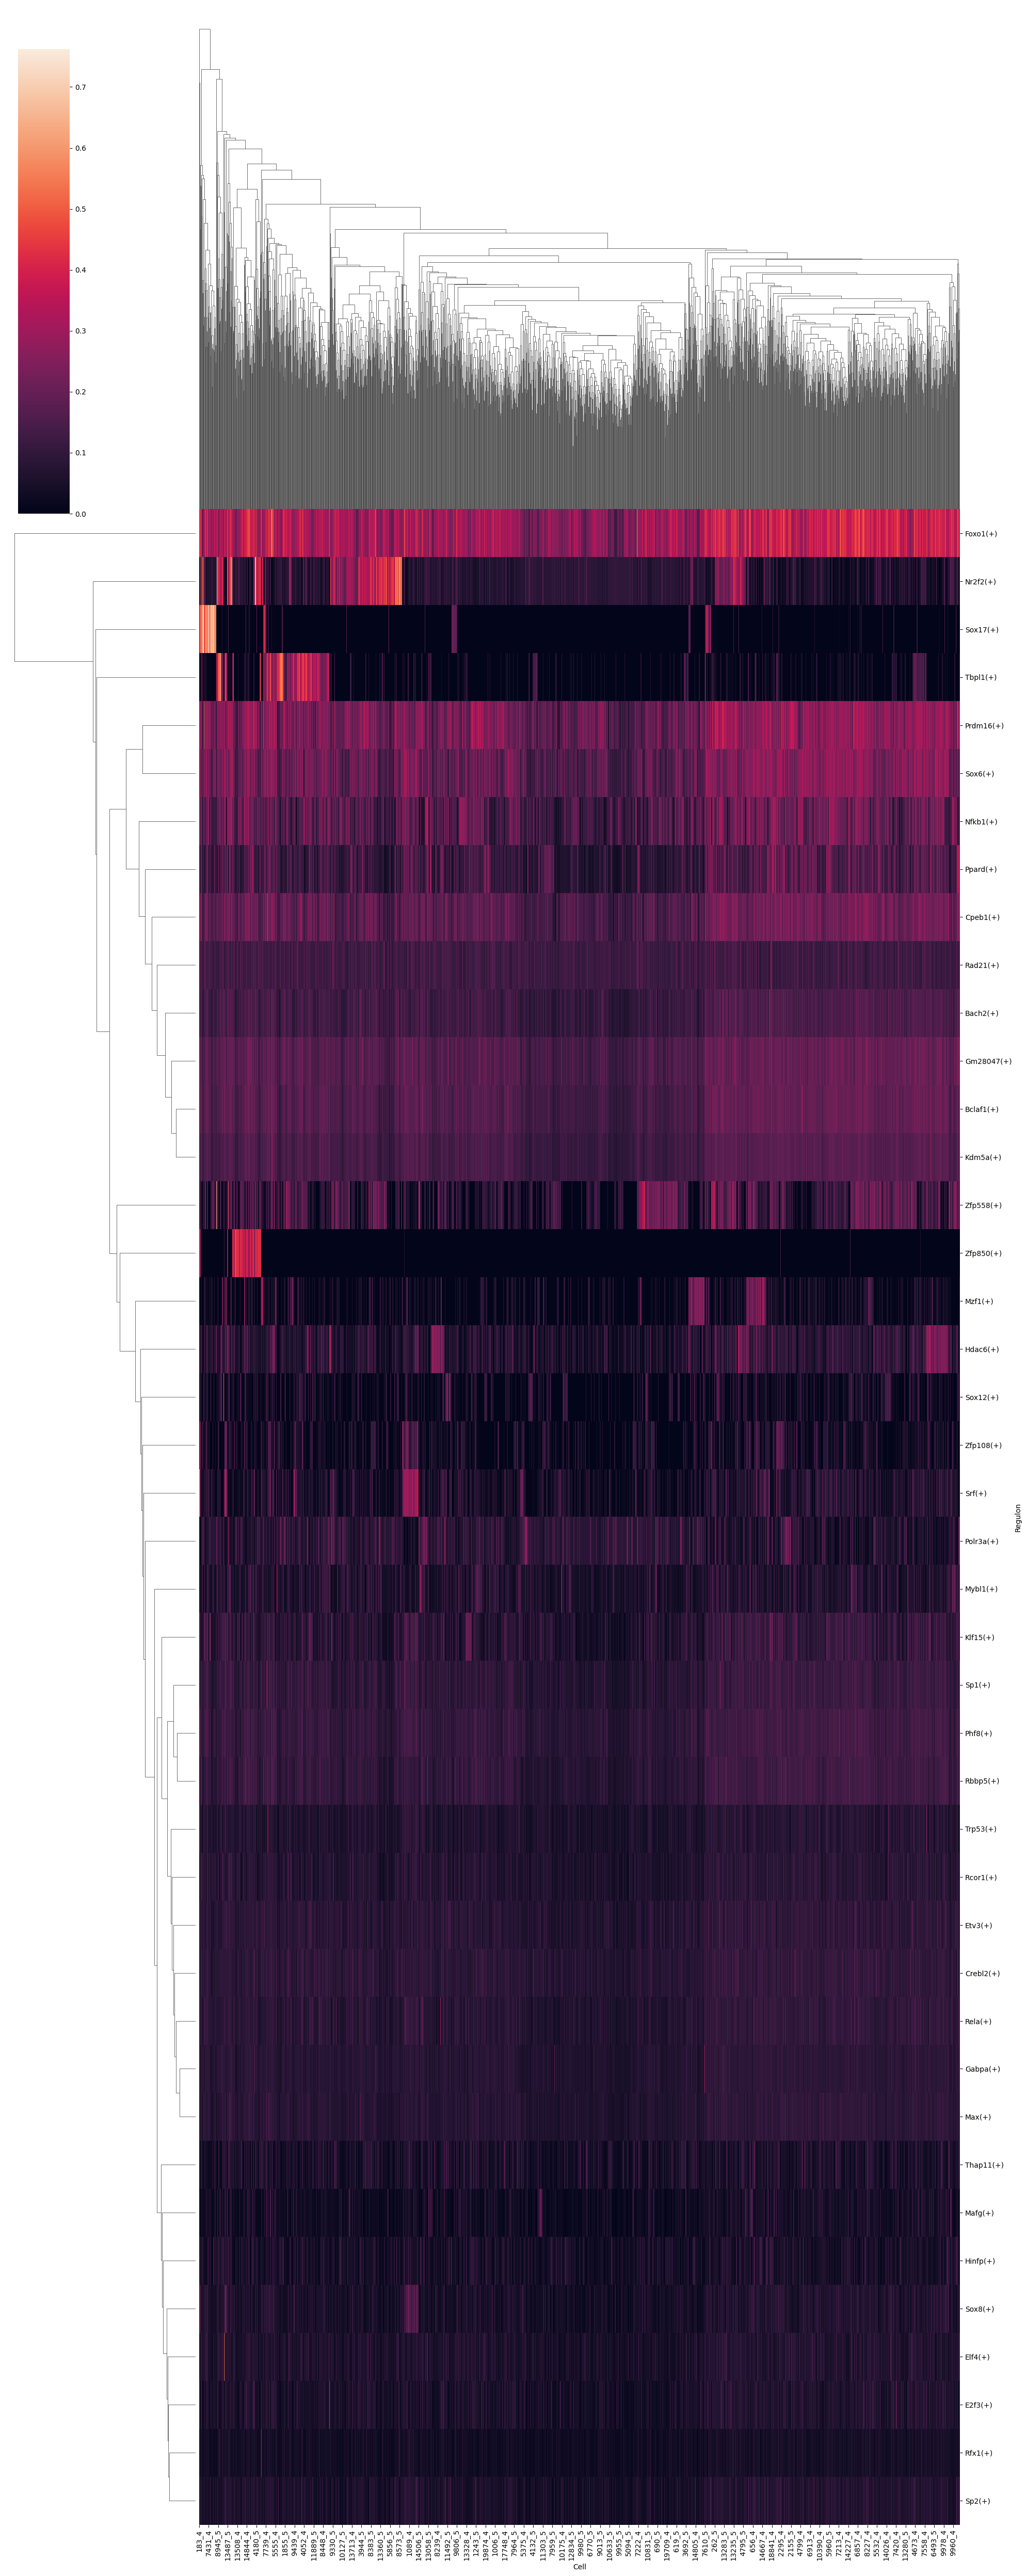

In [ ]:
auc_mtx = aucell(ex_matrix, regulons, num_workers=60)
auc_mtx.to_csv(os.path.join(OUTPUT_DIR, "Glia_auc_matrix.csv"))
# 创建热图
g = sns.clustermap(auc_mtx.T, col_cluster=True, figsize=(20, 50))

# 保存为 PDF 文件
g.savefig("Glia_motif_heatmap.pdf", format="pdf", bbox_inches="tight")

/opt/software/python/lib/python3.8/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


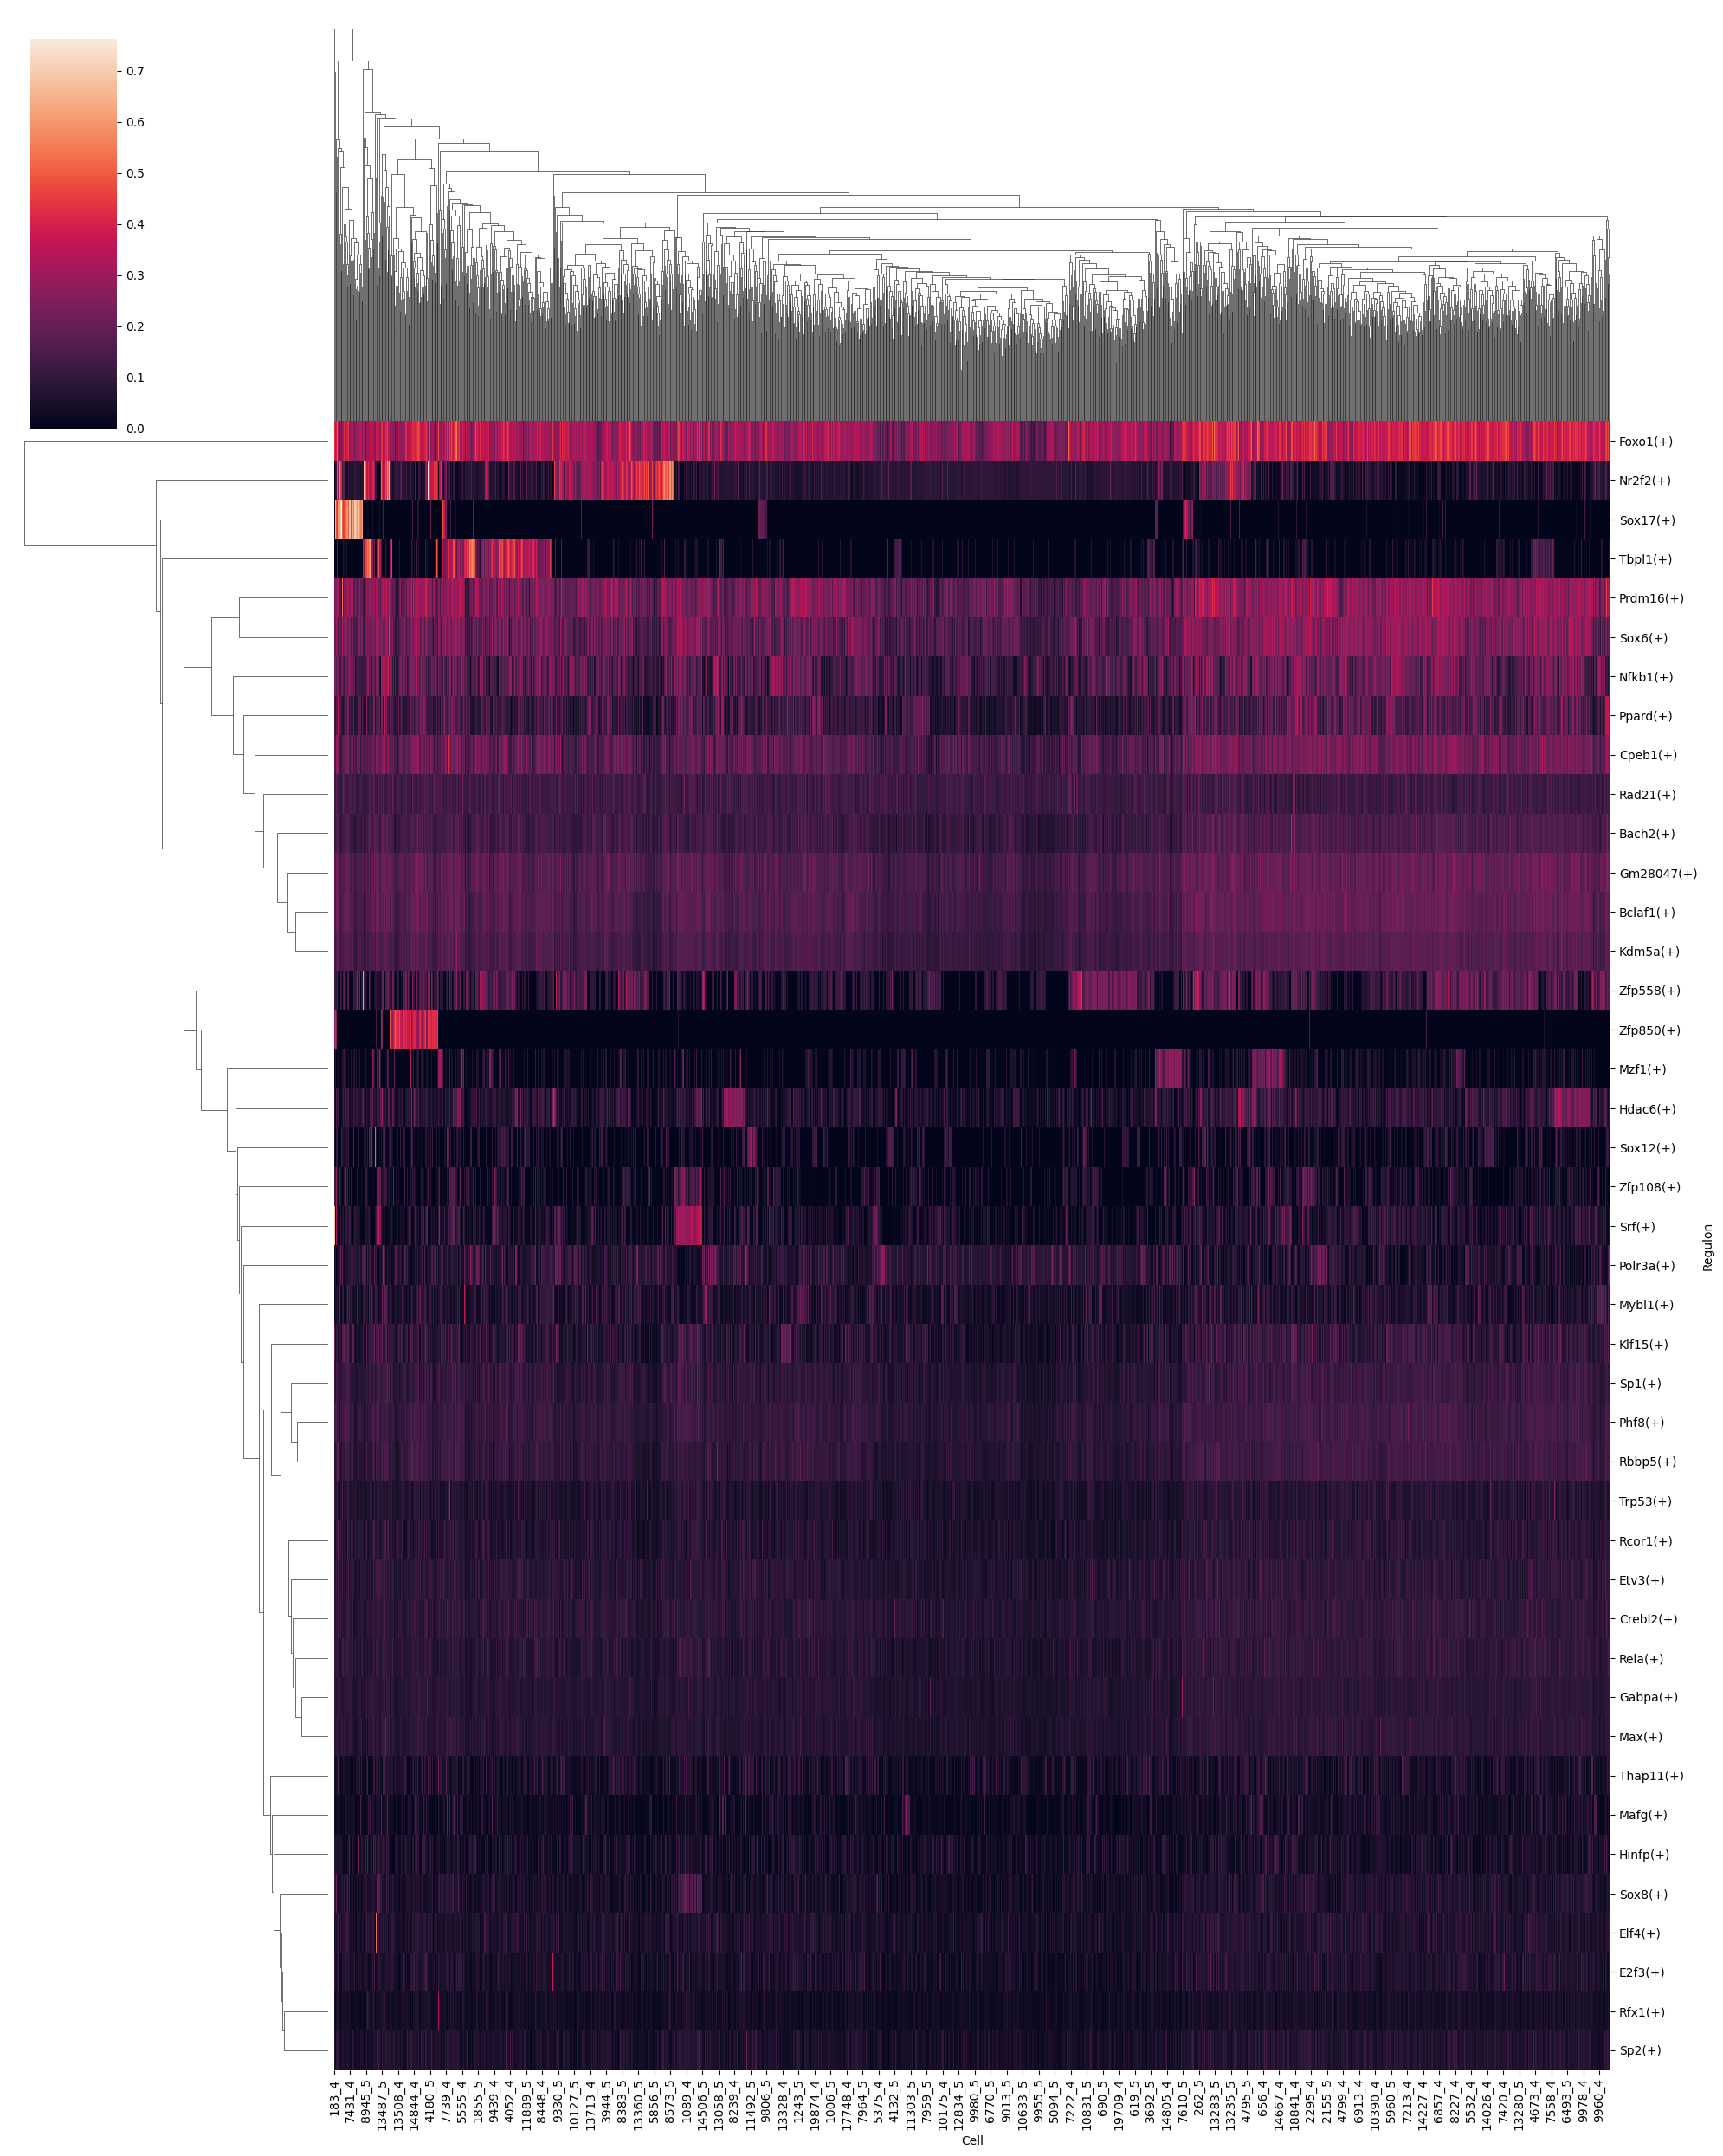

In [ ]:
g = sns.clustermap(auc_mtx.T, col_cluster=True, figsize=(20, 25))

# 保存为 PDF 文件
g.savefig("Glia_motif_heatmap_25.pdf", format="pdf", bbox_inches="tight")

/opt/software/python/lib/python3.8/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


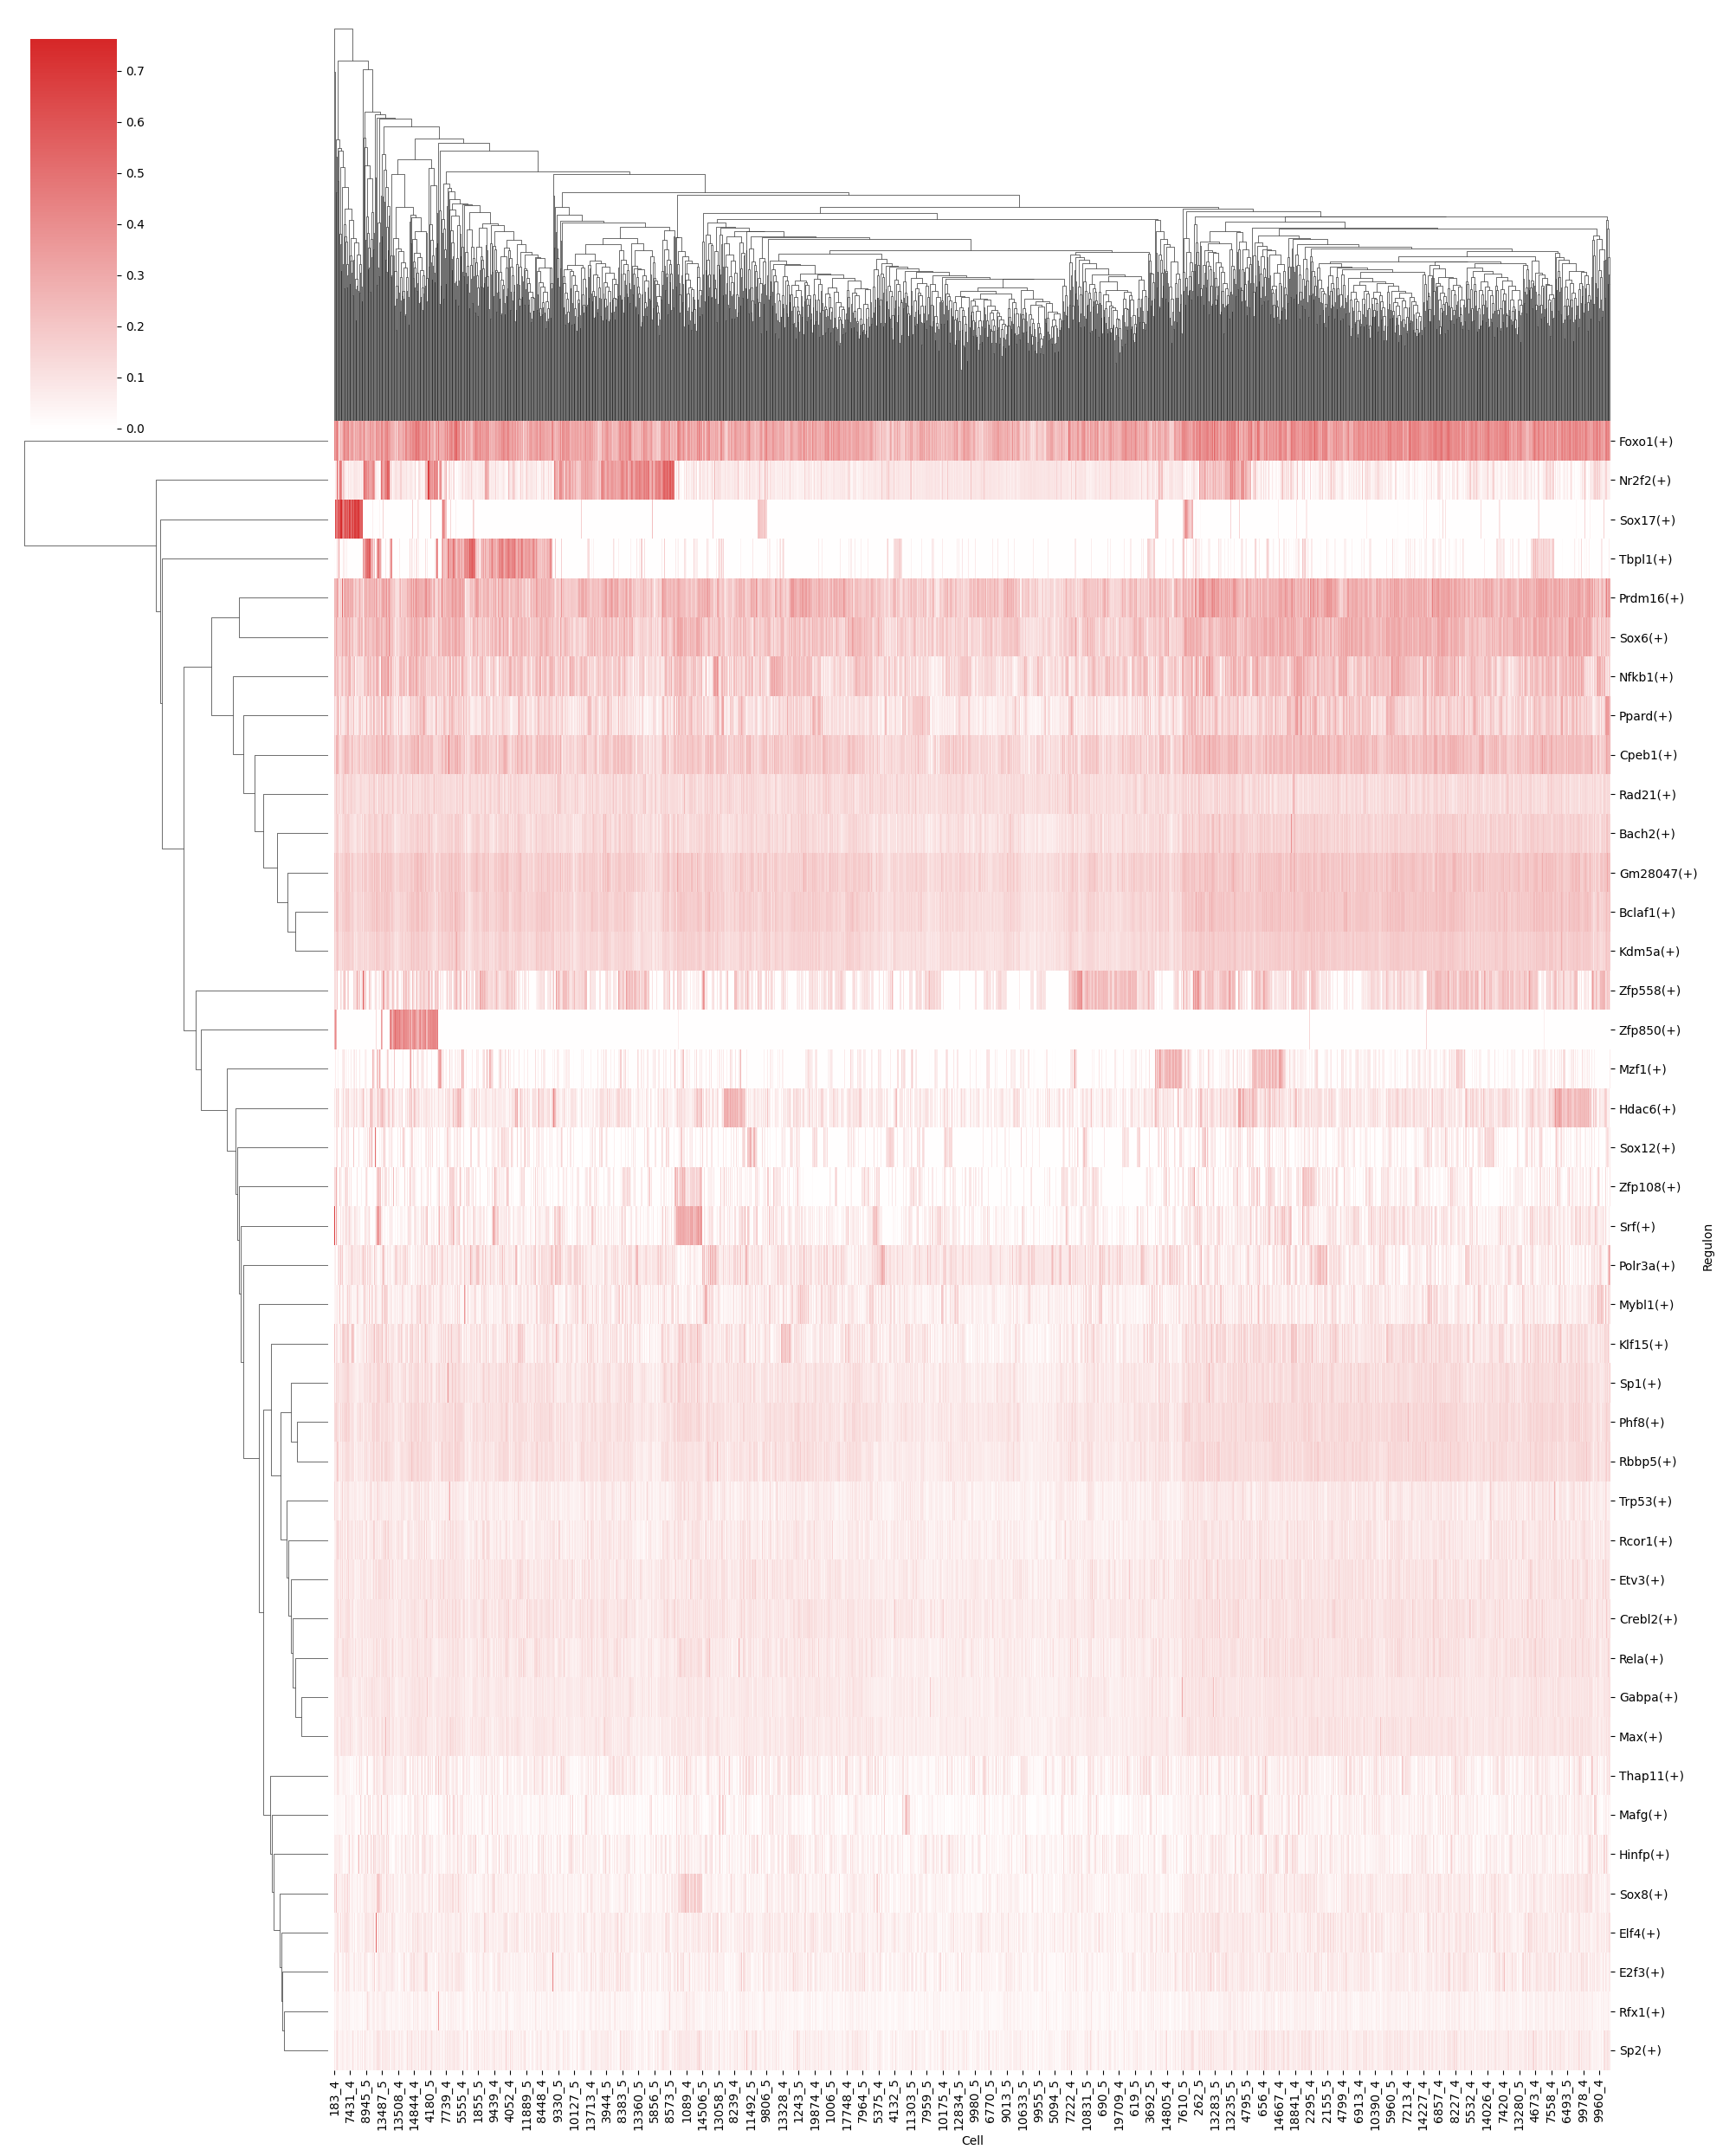

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

custom_cmap = LinearSegmentedColormap.from_list(
    'custom_bwr', ['#1f77b4', '#ffffff', '#d62728']  # 蓝, 白, 红
)

g = sns.clustermap(
    auc_mtx.T,
    col_cluster=True,
    figsize=(20, 25),
    cmap=custom_cmap,  # 使用自定义色彩
    center=0
)
g.savefig("Glia_motif_heatmap_red.pdf", format="pdf", bbox_inches="tight")

In [ ]:
adjacencies["TF"].nunique()

adjacencies["TF"].drop_duplicates().tolist()[:100]

['Zfp9',
 'Eif5a2',
 'Id4',
 'Gm14308',
 'Zfp668',
 'Gli2',
 'Zfp420',
 'Cpeb1',
 'Zfp354c',
 'Pik3c3',
 'Zmat4',
 'Zfp438',
 'Max',
 'Carf',
 'Gtf2f1',
 'Irf6',
 'Terf1',
 '3300002I08Rik',
 'Meis3',
 'Lcorl',
 'Zfp536',
 'Zfp276',
 'Ncald',
 'Zfp28',
 'Kdm5d',
 'Stat3',
 'Prox2',
 'Tfam',
 'Fiz1',
 'Aggf1',
 'Gm29609',
 'Socs4',
 'Hey2',
 'Ikzf1',
 'Zbtb1',
 'Rbbp5',
 'Klf15',
 'Mrps25',
 'Banp',
 'Zkscan8',
 'Hdac6',
 'Zfp560',
 'Hsf1',
 'Rpl6',
 'Cptp',
 'Foxn2',
 'Foxj2',
 'Sp1',
 'Zfp61',
 'Plag1',
 'Vamp3',
 'Zfp286',
 'Zfp639',
 'Polr3g',
 'Stat5b',
 'Ppargc1a',
 'Zfp275',
 'Cat',
 'Mafg',
 'Ecsit',
 'Tcf7l2',
 'Zbtb5',
 'Trerf1',
 'Elk1',
 'Zbtb4',
 'U2af1',
 'Vps72',
 'Utp18',
 'Zfpm1',
 'Xrcc1',
 'Thra',
 'Zfp647',
 'Zfp189',
 'Gm15446',
 'Zfp282',
 'Gm14418',
 'Sall2',
 'Gpam',
 'Gtf2a1',
 'Zfp64',
 'Zfp973',
 'Zfp830',
 'Adnp',
 'Zfp507',
 'Phf21a',
 'Cic',
 'Srp9',
 'Meis1',
 'Zxdb',
 'Zkscan1',
 'Dus3l',
 'Purg',
 'Prdm10',
 'Zfp202',
 'Zfp970',
 'Zeb2',
 'Hnf4g',
 'Zfp86

In [ ]:
set(adjacencies["TF"]) - set(tf_names)

set()

In [ ]:
adata_path = '/data/work/毕业文章/Epi/Merge-Epi-Final-pySCENIC.h5ad'
DATABASES_GLOB = '/data/work/毕业文章/Data/mm10__refseq-r80__*tss.mc9nr.genes_vs_motifs.rankings.feather'
# 需要从 https://resources.aertslab.org/cistarget/databases/mus_musculus/mm9/refseq_r45/mc9nr/gene_based/ 下载
MOTIF_ANNOTATIONS_FNAME = '/data/work/毕业文章/Data/motifs-v9-nr.mgi-m0.001-o0.0.tbl'
# https://resources.aertslab.org/cistarget/motif2tf/
REGULONS_FNAME = '/data/work/毕业文章/Epi/regulons.p'
MOTIFS_FNAME = '/data/work/毕业文章/Epi/motifs.csv'

In [ ]:
# 设置参数
ORGANISM = "mgi"  # 小鼠
OUTPUT_DIR = "Scenic"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. 加载数据 -----------------------------------------------------
adata = sc.read_h5ad(adata_path)

# 确认表达矩阵位置
print(f"表达矩阵形状: {adata.layers['counts'].shape}") 

# 1. 加载目标基因列表（无列名的txt文件）----------------------------------------
#with open("/data/work/其他/SCENIC/Database/hs_hgnc_tfs.txt", "r") as f:
#    target_genes = [line.strip() for line in f if line.strip()]  # 逐行读取并去除空行/空格

#print(f"初始目标基因数量: {len(target_genes)}")

# 2. 准备表达矩阵 ----------------------------------------------------------
# 从layers['counts']创建表达矩阵 (细胞×基因)
ex_matrix = pd.DataFrame(
    adata.layers['counts'].toarray() if scipy.sparse.issparse(adata.layers['counts']) else adata.layers['counts'],
    columns=adata.var_names,
    index=adata.obs_names
)

# 3. 过滤目标基因（确保大小写匹配）-------------------------------------------
#target_genes_in_data = [g for g in target_genes if g in ex_matrix.columns]
#print(f"在数据集中找到的目标基因数量: {len(target_genes_in_data)}")
#filtered_ex_matrix = ex_matrix[target_genes_in_data]

import pandas as pd
from arboreto.algo import grnboost2
import os

# 1. 加载TF列表 ----------------------------------------------------------
tf_list_path = "/data/work/毕业文章/Data/mm_mgi_tfs.txt"
tf_names = load_tf_names(tf_list_path)
# 读取TF列表文件（纯文本，每行一个基因名）
#with open(tf_list_path, 'r') as f:
#    known_tfs = [line.strip() for line in f if line.strip()]  # 去除空白行和每行首尾空格#

#print(f"已知TF数量: {len(known_tfs)}")
#print("示例TF:", known_tfs[:5])  # 检查前5个TF

# 2. 筛选目标基因中的已知TF ----------------------------------------------
# 假设 target_genes_in_data 是你的目标基因列表（Symbol格式）
# target_genes_in_data = [...]  # 你的目标基因列表（需提前定义）

# 取交集：筛选目标基因中真实存在的TF
#tfs_in_target = list(set(target_genes_in_data) & set(known_tfs))

#print(f"目标基因中的已知TF数量: {len(tfs_in_target)}")
#print("示例TF in target:", tfs_in_target[:5])

In [ ]:
print(adata)

AnnData object with n_obs × n_vars = 3588 × 65980
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sample', 'percent.mt', 'RNA_snn_res.0.5', 'seurat_clusters', 'source', 'SN', 'RNA_snn_res.0.8', 'RNA_snn_res.0.4', 'RNA_snn_res.0.3', 'integrated_snn_res.0.3', 'celltype', 'celltype_0813', 'scDblFinder.class', 'scDblFinder.score', 'integrated_snn_res.0.5', 'integrated_snn_res.0.7', 'integrated_snn_res.0.6', 'subtype_Final'
    var: 'features', 'Gene'
    layers: 'counts'


In [ ]:
import scanpy as sc

adata.layers["counts"] = adata.X.copy()

# 1. 数据预处理
sc.pp.filter_genes(adata, min_cells=10)  # 过滤在少于10个细胞中表达的基因
sc.pp.normalize_total(adata, target_sum=1e4)  # 标准化
sc.pp.log1p(adata)  # log转换

# 2. 计算高变基因
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=5000,  # 选择5000个高变基因
    flavor='seurat',   # 使用Seurat的方法
    batch_key=None     # 如果有批次效应，可以指定批次列
)

# 3. 筛选高变基因
adata_hvg = adata[:, adata.var.highly_variable].copy()

# 检查结果
print(f"原始基因数: {adata.n_vars}")
print(f"筛选后高变基因数: {adata_hvg.n_vars}")

原始基因数: 22026
筛选后高变基因数: 5000


In [ ]:
from dask.distributed import Client, LocalCluster
# 降采样到 100,000 个细胞（随机取样）
import numpy as np
from arboreto.algo import grnboost2
from dask.distributed import Client
np.random.seed(42)
# sampled_cells = np.random.choice(ex_matrix.shape[0], size=10000)
# ex_matrix = ex_matrix.iloc[sampled_cells, :]
# client = Client(n_workers=60, threads_per_worker=4)

In [ ]:
hvg_genes = adata.var_names[adata.var.highly_variable]
print(f"高变基因数量: {len(hvg_genes)}")

ex_matrix_hvg = ex_matrix.loc[:, ex_matrix.columns.intersection(hvg_genes)]
print(f"筛选后的表达矩阵形状: {ex_matrix_hvg.shape}")
# 假设tf_names是之前加载的TF列表
tf_names_hvg = list(set(tf_names) & set(hvg_genes))
print(f"高变基因中的TF数量: {len(tf_names_hvg)}")

高变基因数量: 5000
筛选后的表达矩阵形状: (3588, 5000)
高变基因中的TF数量: 226


In [ ]:
client = Client(n_workers=60, threads_per_worker=8)
# 运行 GRNBoost2
adjacencies = grnboost2(
    expression_data=ex_matrix_hvg,
    tf_names=tf_names,
    client_or_address=client,
    verbose=True# 显式传递 client
)

/opt/software/python/lib/python3.8/site-packages/distributed/node.py:182: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 39831 instead
  warnings.warn(


preparing dask client
parsing input
creating dask graph
60 partitions
computing dask graph


/opt/software/python/lib/python3.8/site-packages/distributed/client.py:3108: UserWarning: Sending large graph of size 139.25 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


not shutting down client, client was created externally
finished


In [ ]:
# 保存结果
adjacencies.to_csv(os.path.join(OUTPUT_DIR, "Epi_adjacencies.csv"), index=False)
print(f"生成的调控关系数量: {len(adjacencies)}")

生成的调控关系数量: 345947


In [ ]:
db_fnames = glob.glob(DATABASES_GLOB)
def name(fname):
    return os.path.splitext(os.path.basename(fname))[0]
dbs = [RankingDatabase(fname=fname, name=name(fname)) for fname in db_fnames]
dbs

#从共表达网络构建模块
modules = list(modules_from_adjacencies(adjacencies, ex_matrix))

# 提取所有 Regulon 的 TF、靶基因和权重
data = []
for regulon in modules:
    tf = regulon.name.replace('Regulon for ', '')  # 从 "Regulon for HMGA1" 提取 "HMGA1"
    for target, weight in regulon.gene2weight.items():
        data.append({"TF": tf, "Target": target, "Weight": weight})

# 转换为 DataFrame 并保存
df = pd.DataFrame(data)
df.to_csv("Epi_regulons_tf_target_weight.csv", index=False)


2026-10-14 23:08:28,916 - pyscenic.utils - INFO - Calculating Pearson correlations.

2026-10-14 23:08:29,044 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2026-10-14 23:08:32,951 - pyscenic.utils - INFO - Creating modules.


In [ ]:
# 读取 CSV 文件
df = pd.read_csv("Epi_regulons_tf_target_weight.csv") 

# 按 TF 分组，统计每个 TF 的靶基因数量
tf_stats = df.groupby("TF").agg(
    Num_Targets=("Target", "count"),      # 统计靶基因数量
    Target_List=("Target", lambda x: "、".join(x)),  # 用顿号连接所有靶基因
    Mean_Weight=("Weight", "mean")        # 计算平均权重
).reset_index()

# 保存结果
tf_stats.to_csv("Epi_tf_summary.csv", index=False, encoding="utf-8-sig")
print("统计结果已保存为: Epi_tf_summary.csv")

统计结果已保存为: Epi_tf_summary.csv


In [ ]:
# 计算富集基序
# Calculate a list of enriched motifs and the corresponding target genes for all modules.
with ProgressBar():
    df = prune2df(dbs, modules, MOTIF_ANNOTATIONS_FNAME)

# Create regulons from this table of enriched motifs.
regulons = df2regulons(df)

[                                        ] | 0% Completed | 105.21 ms

/opt/software/python/lib/python3.8/site-packages/dask/base.py:1368: UserWarning: Running on a single-machine scheduler when a distributed client is active might lead to unexpected results.
  warnings.warn(


[                                        ] | 0% Completed | 65.23 sms


2026-10-14 23:10:08,621 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for 5730507C01Rik could be mapped to mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.

2026-10-14 23:10:08,654 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for Spr could be mapped to mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.

2026-10-14 23:10:08,767 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for Ssrp1 could be mapped to mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.


[                                        ] | 0% Completed | 65.43 s

...

[###############################         ] | 78% Completed | 217.64 s


2026-10-14 23:12:41,014 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for Sp100 could be mapped to mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.


[###################################     ] | 89% Completed | 218.25 s


2026-10-14 23:12:41,674 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for Sp4 could be mapped to mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.genes_vs_motifs.rankings. Skipping this module.


[########################################] | 100% Completed | 218.65 s
Create regulons from a dataframe of enriched features.
Additional columns saved: []


In [ ]:
# Save the enriched motifs and the discovered regulons to disk.
df.to_csv(MOTIFS_FNAME)
with open(REGULONS_FNAME, "wb") as f:
    pickle.dump(regulons, f)

num_regulons = len(regulons)
print(f"Number of regulons: {num_regulons}")

Number of regulons: 10


/opt/software/python/lib/python3.8/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


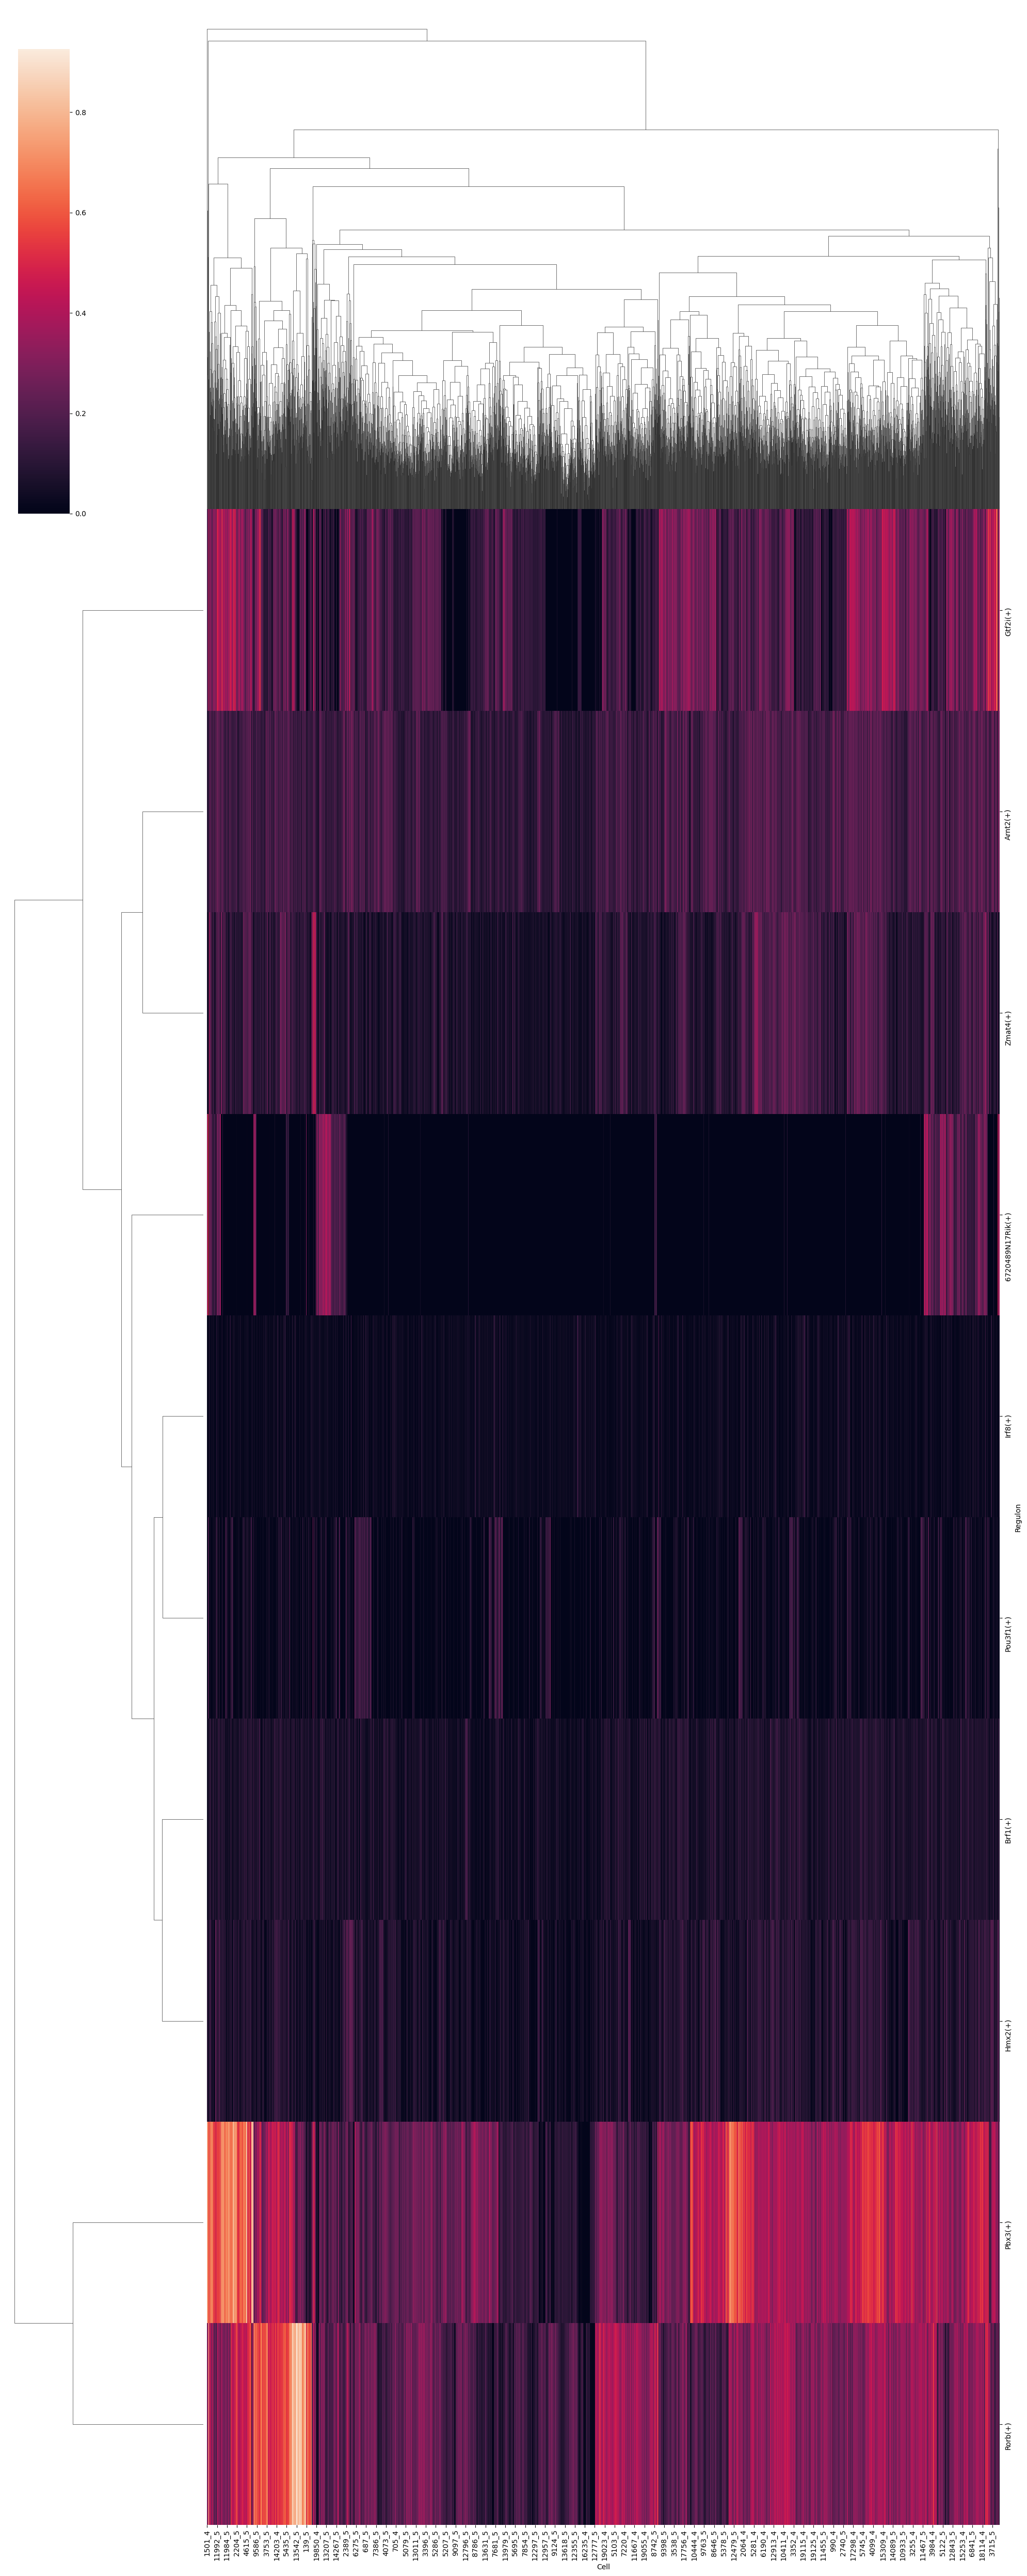

In [ ]:
auc_mtx = aucell(ex_matrix, regulons, num_workers=60)
auc_mtx.to_csv(os.path.join(OUTPUT_DIR, "Epi_auc_matrix.csv"))
# 创建热图
g = sns.clustermap(auc_mtx.T, col_cluster=True, figsize=(20, 50))

# 保存为 PDF 文件
g.savefig("Epi_motif_heatmap.pdf", format="pdf", bbox_inches="tight")

/opt/software/python/lib/python3.8/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


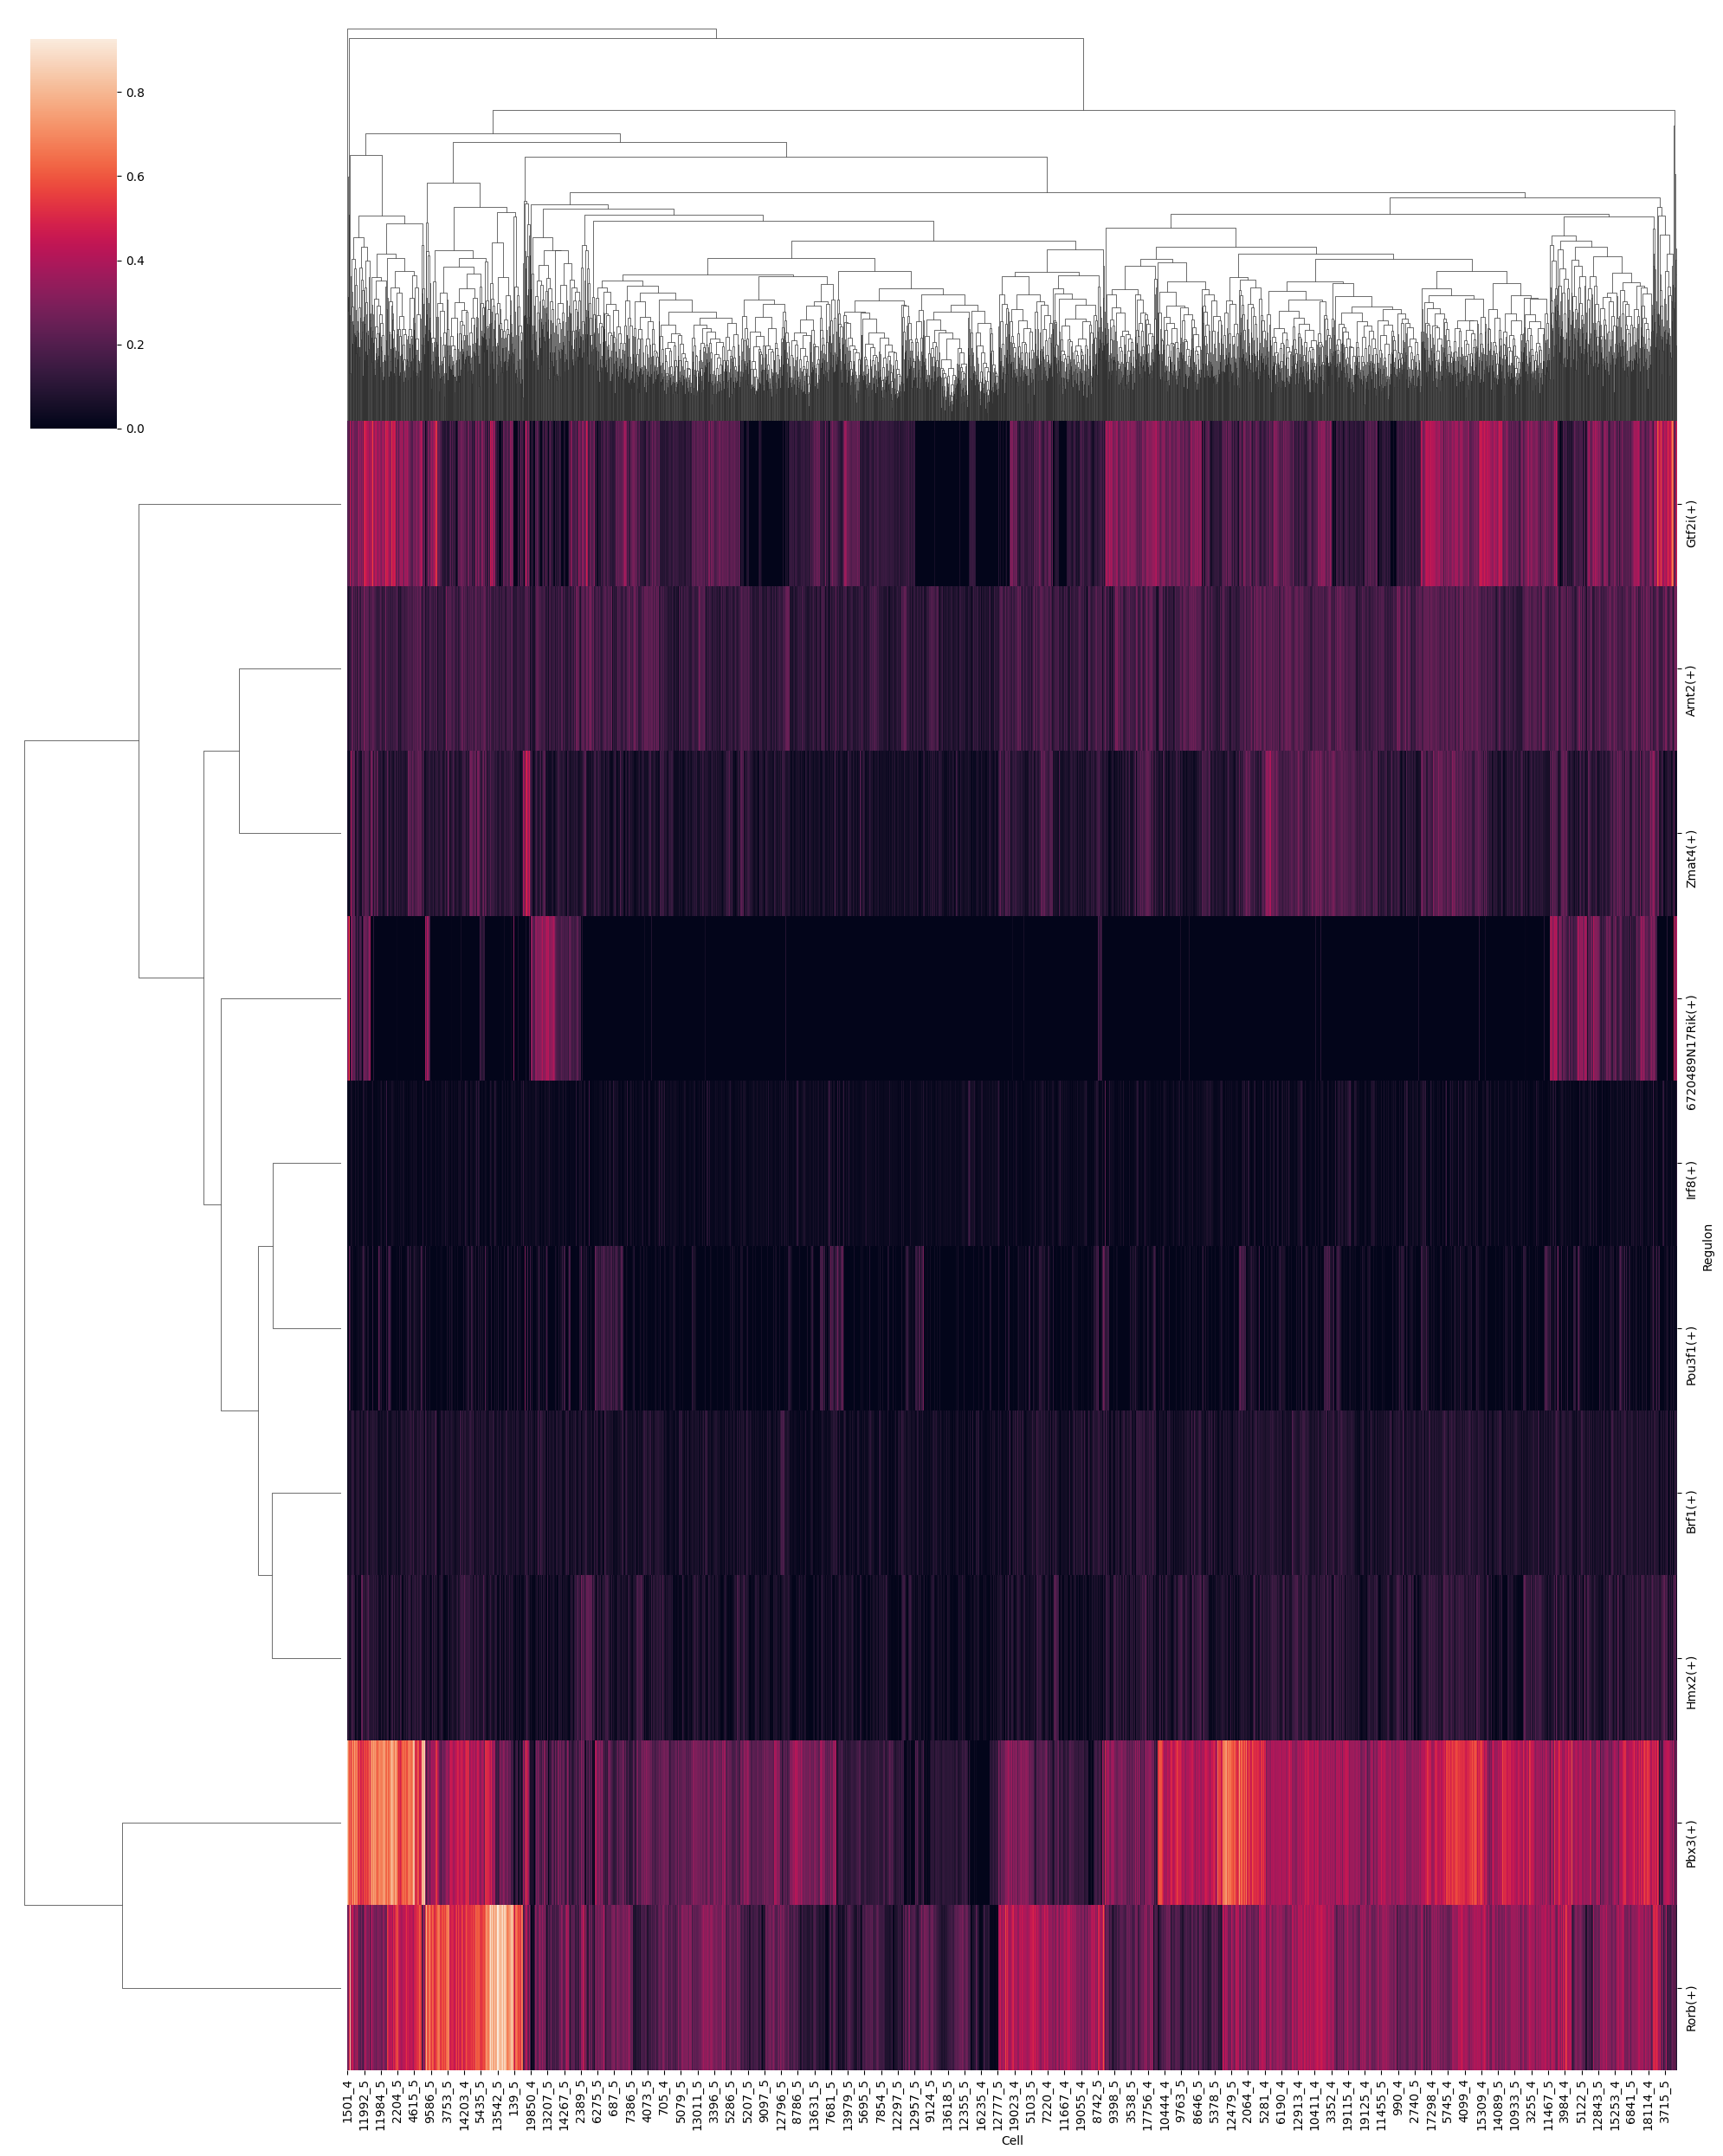

In [ ]:
g = sns.clustermap(auc_mtx.T, col_cluster=True, figsize=(20, 25))

# 保存为 PDF 文件
g.savefig("Epi_motif_heatmap_25.pdf", format="pdf", bbox_inches="tight")

/opt/software/python/lib/python3.8/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


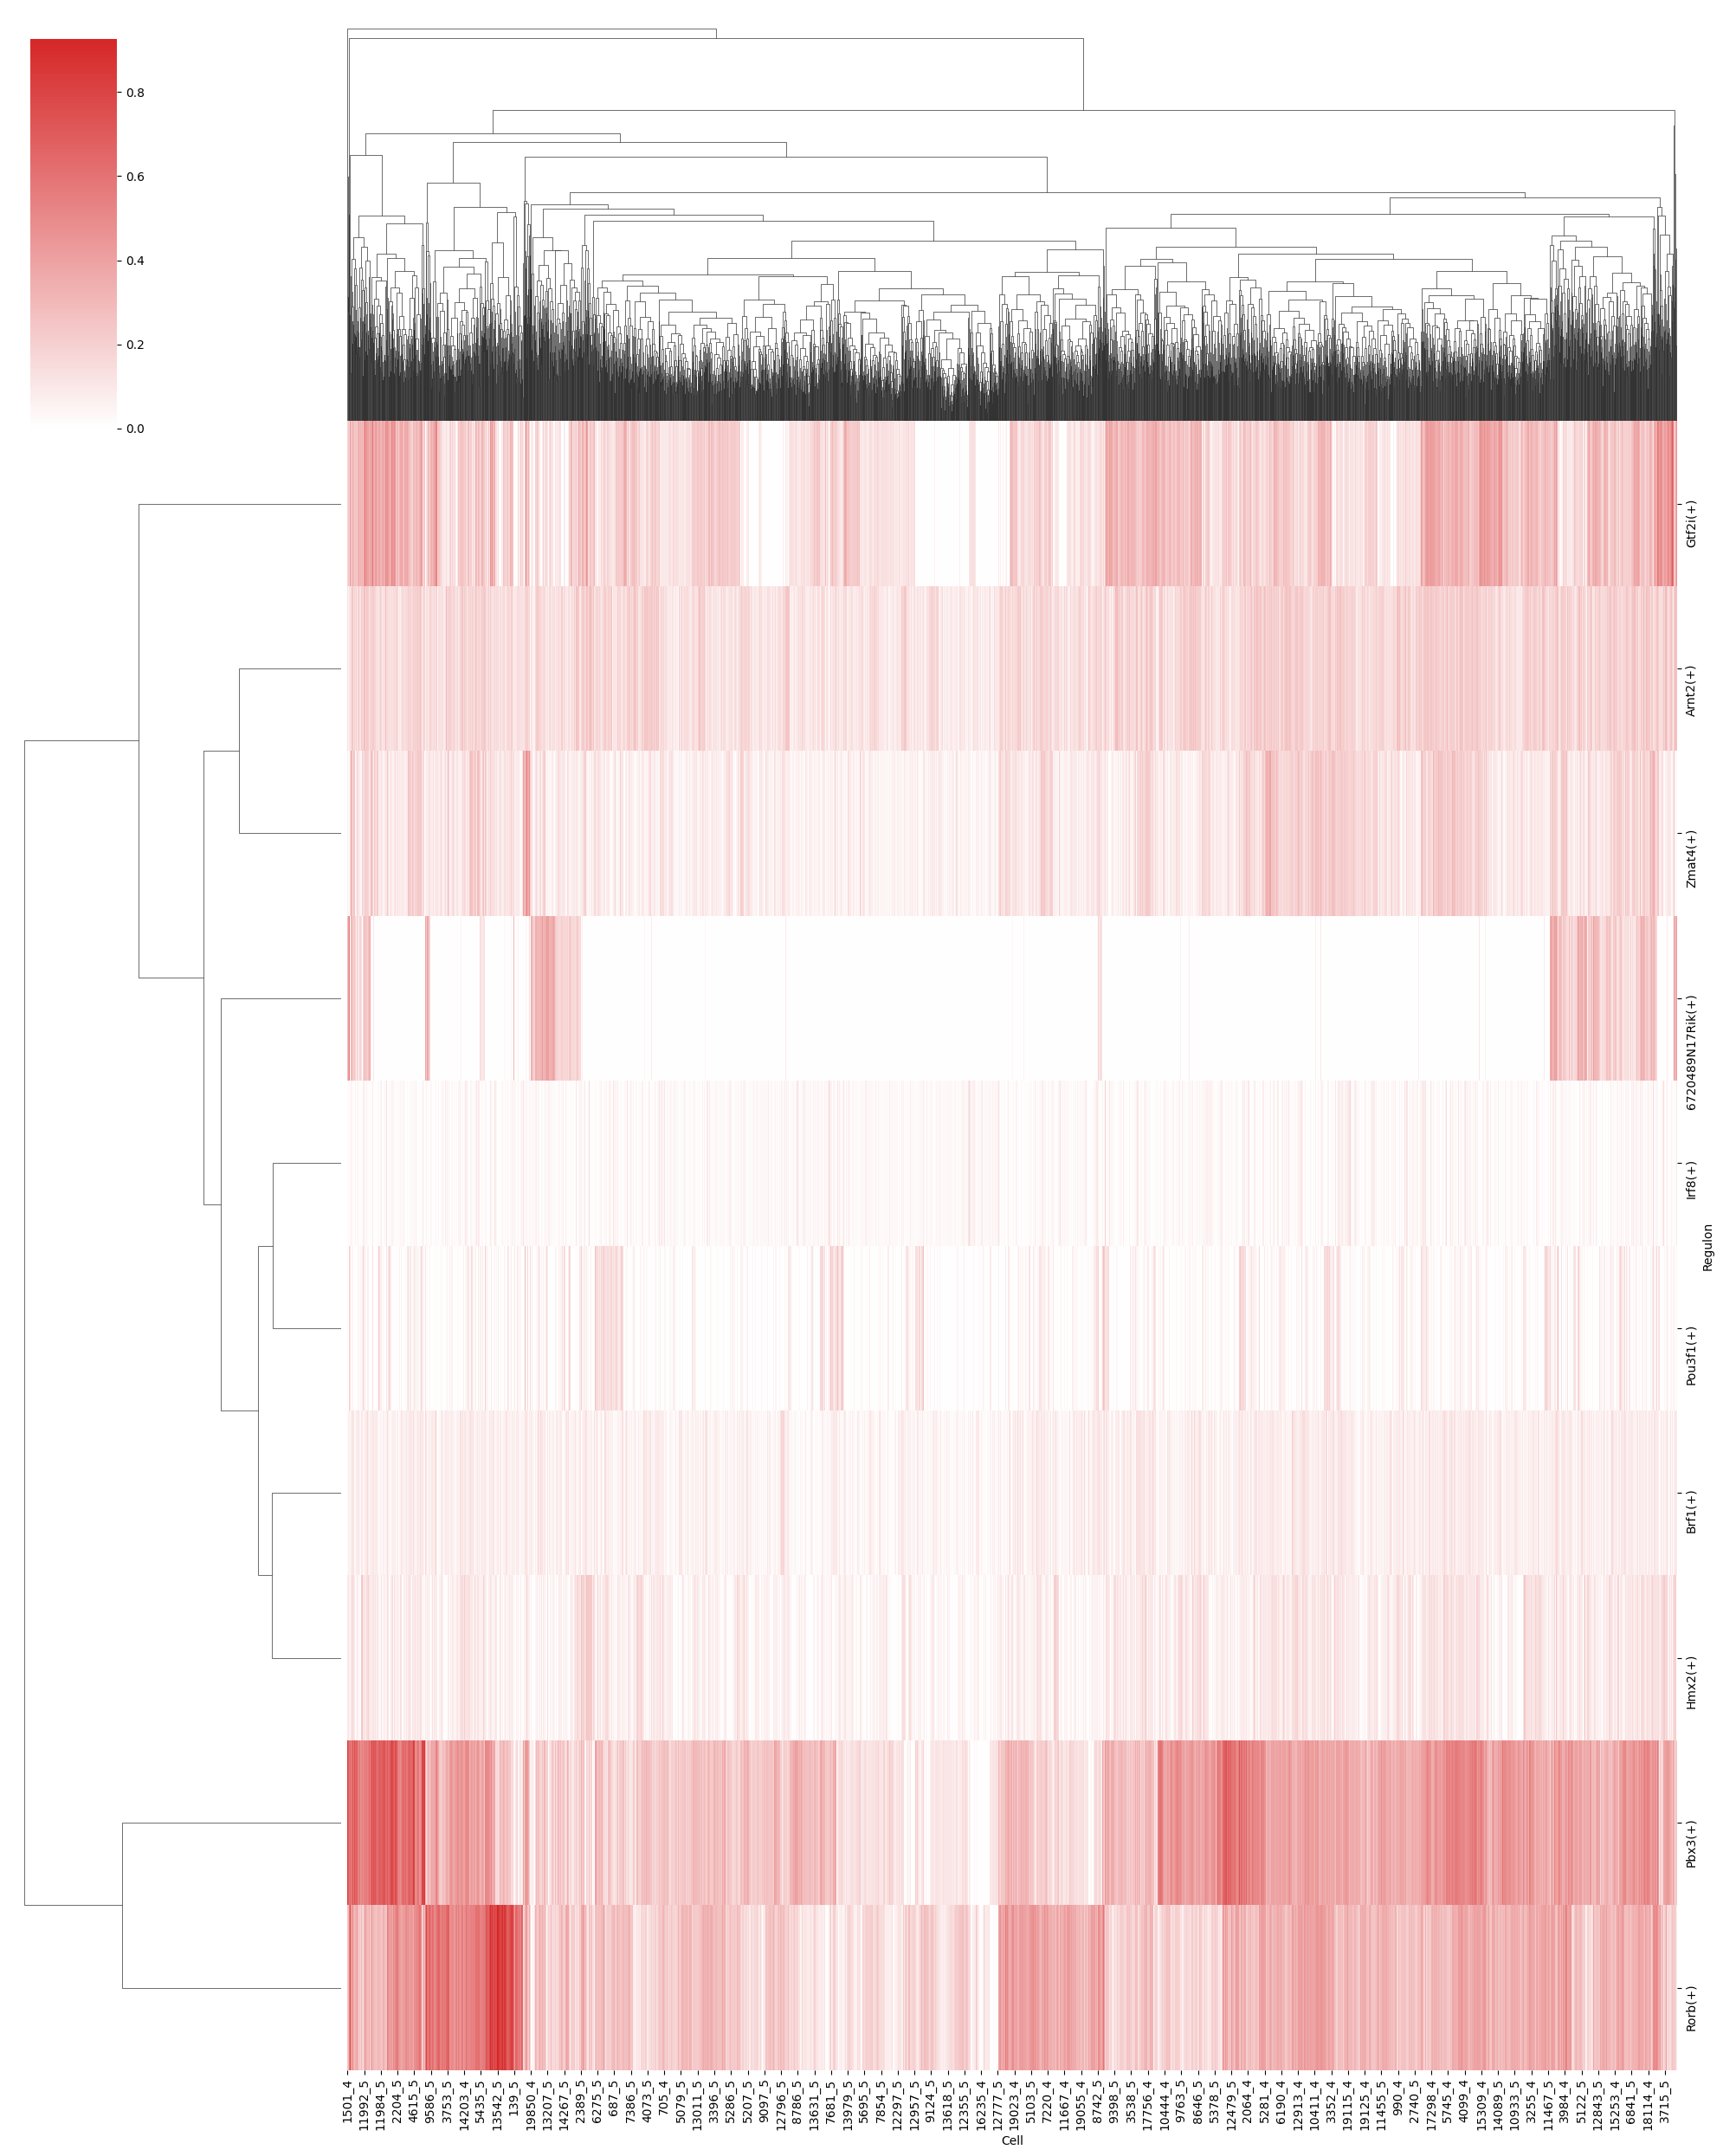

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

custom_cmap = LinearSegmentedColormap.from_list(
    'custom_bwr', ['#1f77b4', '#ffffff', '#d62728']  # 蓝, 白, 红
)

g = sns.clustermap(
    auc_mtx.T,
    col_cluster=True,
    figsize=(20, 25),
    cmap=custom_cmap,  # 使用自定义色彩
    center=0
)
g.savefig("Epi_motif_heatmap_red.pdf", format="pdf", bbox_inches="tight")